Project Task-1 EDA
CSE475
Sec01
Fall2026

Name                        ID
Samia Hasan             2023-3-60-556
Shuvro Dev Sil          2023-3-60-224
Annur Tasnia            2023-3-60-429
Samia Naba              2023-3-60-578


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import loadmat
from scipy.signal import welch

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


**Find and extract the ZIP file**

In [2]:
from pathlib import Path
import zipfile

INPUT_DIR = Path("/kaggle/input/datasets/annurtasnia/mlproject")
WORK_DIR  = Path("/kaggle/working/semg_eda")
WORK_DIR.mkdir(parents=True, exist_ok=True)


mat_files = sorted(INPUT_DIR.rglob("*.mat"))

if mat_files:
    DATA_ROOT = INPUT_DIR
    print("Using already-extracted MATLAB files.")
else:
    
    zip_files = list(INPUT_DIR.rglob("*.zip"))
    if not zip_files:
        raise FileNotFoundError(f"No .mat or .zip found inside {INPUT_DIR}")
    ZIP_PATH = zip_files[0]
    print("ZIP found:", ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(WORK_DIR)
    DATA_ROOT = WORK_DIR
    mat_files = sorted(DATA_ROOT.rglob("*.mat"))

print("Number of MATLAB files:", len(mat_files))
for f in mat_files:
    print(f.relative_to(DATA_ROOT))

Using already-extracted MATLAB files.
Number of MATLAB files: 8
Database 1/female_1.mat
Database 1/female_2.mat
Database 1/female_3.mat
Database 1/male_1.mat
Database 1/male_2.mat
Database 2/male_day_1.mat
Database 2/male_day_2.mat
Database 2/male_day_3.mat


**Load MATLAB files and build a trial-level dataset**

In [4]:

all_vars = set()
for f in mat_files:
    m = loadmat(f)
    all_vars |= {k for k in m.keys() if not k.startswith("__")}

MOVEMENTS = sorted({v.rsplit("_", 1)[0] for v in all_vars})
CHANNELS  = sorted({v.rsplit("_", 1)[1] for v in all_vars})

print("Movements:", MOVEMENTS)
print("Channels :", CHANNELS)


records = []
file_summary = []

for file_path in mat_files:

    mat = loadmat(file_path)

    relative_path = file_path.relative_to(DATA_ROOT).as_posix()

   
    rel_lower = relative_path.lower().replace("_", " ")
    if "database 1" in rel_lower:
        database = "Database 1"
    elif "database 2" in rel_lower:
        database = "Database 2"
    else:
        database = "Unknown"

    source_id = file_path.stem

    for movement in MOVEMENTS:
        for channel in CHANNELS:

            key = f"{movement}_{channel}"

            if key not in mat:
                print("Missing variable:", key, "in", relative_path)
                continue

            arr = np.asarray(mat[key], dtype=np.float64)

            if arr.ndim != 2:
                print("Unexpected shape:", key, arr.shape)
                continue

            file_summary.append({
                "file": relative_path,
                "database": database,
                "movement": movement,
                "channel": channel,
                "n_trials": arr.shape[0],
                "n_samples": arr.shape[1]
            })

            for trial_idx, signal in enumerate(arr):
                records.append({
                    "database": database,
                    "source_file": relative_path,
                    "source_id": source_id,
                    "movement": movement,
                    "trial": trial_idx + 1,
                    "channel": channel,
                    "signal": signal.copy()
                })

df = pd.DataFrame(records)
summary_df = pd.DataFrame(file_summary)

print("\nTotal channel-level recordings:", len(df))
print("Unique source files:", df["source_file"].nunique())
print("Movement classes:", sorted(df["movement"].unique()))

display(df.head())
display(summary_df.head(12))

Movements: ['cyl', 'hook', 'lat', 'palm', 'spher', 'tip']
Channels : ['ch1', 'ch2']

Total channel-level recordings: 5400
Unique source files: 8
Movement classes: ['cyl', 'hook', 'lat', 'palm', 'spher', 'tip']


,database,source_file,source_id,movement,trial,channel,signal
0,Database 1,Database 1/female_1.mat,female_1,cyl,1,ch1,"[0.072198, 0.276211, 0.429221, 0.327214, 0.123..."
1,Database 1,Database 1/female_1.mat,female_1,cyl,2,ch1,"[0.25071, 0.301713, 0.199706, 0.378218, 0.0211..."
2,Database 1,Database 1/female_1.mat,female_1,cyl,3,ch1,"[0.123201, 0.148703, 0.148703, 0.123201, -0.00..."
3,Database 1,Database 1/female_1.mat,female_1,cyl,4,ch1,"[0.531228, -0.106313, -0.284825, -0.335828, -0..."
4,Database 1,Database 1/female_1.mat,female_1,cyl,5,ch1,"[-0.310326, -0.182818, 0.276211, 0.480224, 0.3..."


,file,database,movement,channel,n_trials,n_samples
0,Database 1/female_1.mat,Database 1,cyl,ch1,30,3000
1,Database 1/female_1.mat,Database 1,cyl,ch2,30,3000
2,Database 1/female_1.mat,Database 1,hook,ch1,30,3000
3,Database 1/female_1.mat,Database 1,hook,ch2,30,3000
4,Database 1/female_1.mat,Database 1,lat,ch1,30,3000
5,Database 1/female_1.mat,Database 1,lat,ch2,30,3000
6,Database 1/female_1.mat,Database 1,palm,ch1,30,3000
7,Database 1/female_1.mat,Database 1,palm,ch2,30,3000
8,Database 1/female_1.mat,Database 1,spher,ch1,30,3000
9,Database 1/female_1.mat,Database 1,spher,ch2,30,3000


**Summary Statistics**

In [5]:
print("Rows        :", len(df), "(expected 5400)")
print("Summary rows:", len(summary_df), "(expected 96)")
print("Unknown db  :", (df["database"] == "Unknown").sum(), "(expected 0)")
print(df.groupby("database")["source_file"].nunique())
print(summary_df.groupby("database")[["n_trials", "n_samples"]].agg(["min", "max"]))

Rows        : 5400 (expected 5400)
Summary rows: 96 (expected 96)
Unknown db  : 0 (expected 0)
database
Database 1    5
Database 2    3
Name: source_file, dtype: int64
           n_trials      n_samples      
                min  max       min   max
database                                
Database 1       30   30      3000  3000
Database 2      100  100      2500  2500


**Dataset overview and data quality check**

In [6]:
print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)

# One "trial" = one (file, movement, trial) that has both channels
n_trials = df.groupby(["source_file", "movement", "trial"]).ngroups
print("Total channel-level rows :", len(df))
print("Total files              :", df["source_file"].nunique())
print("Total trials (2 ch each) :", n_trials)
print("Movement classes         :", df["movement"].nunique(), sorted(df["movement"].unique()))
print("Channels                 :", df["channel"].nunique(), sorted(df["channel"].unique()))
print("Databases                :", df["database"].nunique())

print("\nFiles / trials / rows per database:")
display(df.groupby("database").agg(
    files=("source_file", "nunique"),
    trials=("trial", "size"),          # channel-level rows
    max_trial_idx=("trial", "max")).assign(trials=lambda d: d["trials"] // df["channel"].nunique()))

print("\nSignal length distribution:")
len_df = df.assign(n_samples=df["signal"].map(len))
display(len_df.groupby(["database", "channel", "n_samples"]).size().rename("count").reset_index())

print("\nTrials per source file x movement (balance check):")
display(df[df.channel == sorted(df.channel.unique())[0]]
        .pivot_table(index=["database", "source_id"], columns="movement", values="trial", aggfunc="count"))

print("\nDatabase-wise recording summary:")
display(summary_df.groupby(["database", "movement", "channel"])[["n_trials", "n_samples"]].agg(["min", "max"]))

print("\nMissing values in metadata:")
display(df.drop(columns=["signal"]).isnull().sum())

# Signal-level quality check
quality = []
for row in df.itertuples(index=False):
    x = row.signal
    quality.append({
        "source_file": row.source_file, "database": row.database,
        "movement": row.movement, "channel": row.channel, "trial": row.trial,
        "n_samples": len(x),
        "nan_count": int(np.isnan(x).sum()),
        "inf_count": int(np.isinf(x).sum()),
        "all_zero": bool(np.all(x == 0)),
        "is_flat": bool(np.ptp(x) == 0),
        "mean": np.nanmean(x), "std": np.nanstd(x),
        "min": np.nanmin(x), "max": np.nanmax(x),
    })
quality_df = pd.DataFrame(quality)

display(quality_df.head())
print("\nQuality totals:")
display(quality_df[["nan_count", "inf_count", "all_zero", "is_flat"]].sum())

# Duplicate-signal check (same trial recorded twice / copy-paste errors)
dup = df["signal"].map(lambda s: s.tobytes()).duplicated(keep=False)
print("Duplicated signals:", int(dup.sum()))

# Very low-variance signals (possible dead electrode)
low = quality_df["std"] < quality_df["std"].quantile(0.01) * 0.1
print("Suspiciously low-std signals:", int(low.sum()))

DATASET OVERVIEW
Total channel-level rows : 5400
Total files              : 8
Total trials (2 ch each) : 2700
Movement classes         : 6 ['cyl', 'hook', 'lat', 'palm', 'spher', 'tip']
Channels                 : 2 ['ch1', 'ch2']
Databases                : 2

Files / trials / rows per database:


,files,trials,max_trial_idx
database,,,
Database 1,5,900,30
Database 2,3,1800,100



Signal length distribution:


,database,channel,n_samples,count
0,Database 1,ch1,3000,900
1,Database 1,ch2,3000,900
2,Database 2,ch1,2500,1800
3,Database 2,ch2,2500,1800



Trials per source file x movement (balance check):


...

database       0
source_file    0
source_id      0
movement       0
trial          0
channel        0
dtype: int64

,source_file,database,movement,channel,trial,n_samples,nan_count,inf_count,all_zero,is_flat,mean,std,min,max
0,Database 1/female_1.mat,Database 1,cyl,ch1,1,3000,0,0,False,False,0.141044,0.840739,-5.053630,4.024951
1,Database 1/female_1.mat,Database 1,cyl,ch1,2,3000,0,0,False,False,0.140636,0.799169,-6.634731,3.540420
2,Database 1/female_1.mat,Database 1,cyl,ch1,3,3000,0,0,False,False,0.138800,0.748804,-4.977125,2.851876
3,Database 1/female_1.mat,Database 1,cyl,ch1,4,3000,0,0,False,False,0.139760,0.856790,-6.405217,2.953883
4,Database 1/female_1.mat,Database 1,cyl,ch1,5,3000,0,0,False,False,0.138808,0.872892,-5.053630,3.616925



Quality totals:


nan_count    0
inf_count    0
all_zero     0
is_flat      0
dtype: int64

Duplicated signals: 0
Suspiciously low-std signals: 0


**Correct trial count and class distribution**

Total trials: 2700

Trials by database:


,database,trials
0,Database 1,900
1,Database 2,1800


,movement,count,percent
0,cyl,450,16.67
1,hook,450,16.67
2,lat,450,16.67
3,palm,450,16.67
4,spher,450,16.67
5,tip,450,16.67


Imbalance ratio (max/min): 1.00 -> balanced

Trials: movement x database


database,Database 1,Database 2,All
movement,,,
cyl,150,300,450
hook,150,300,450
lat,150,300,450
palm,150,300,450
spher,150,300,450
tip,150,300,450
All,900,1800,2700



Trials: movement x source (subject/day)


source_id,female_1,female_2,female_3,male_1,male_2,male_day_1,male_day_2,male_day_3,All
movement,,,,,,,,,
cyl,30,30,30,30,30,100,100,100,450
hook,30,30,30,30,30,100,100,100,450
lat,30,30,30,30,30,100,100,100,450
palm,30,30,30,30,30,100,100,100,450
spher,30,30,30,30,30,100,100,100,450
tip,30,30,30,30,30,100,100,100,450
All,180,180,180,180,180,600,600,600,2700


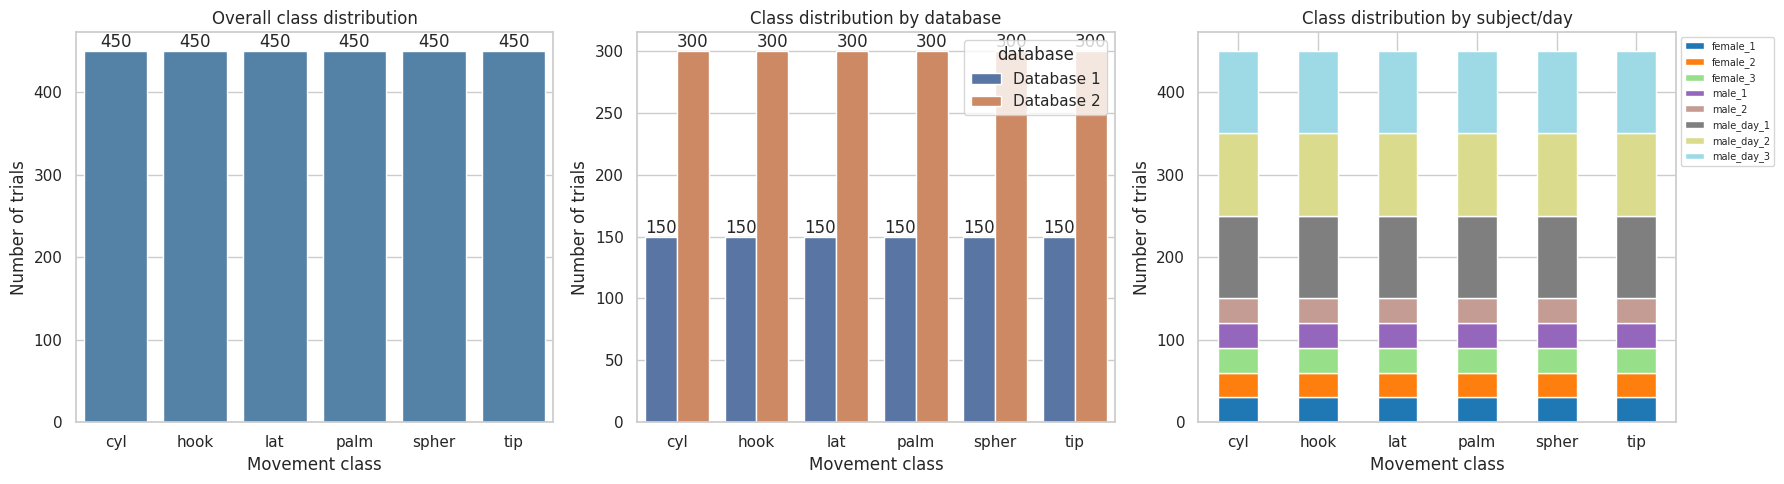

In [7]:
# One row per trial (the 2 channels of a trial are merged into one row)
trial_df = (
    df.drop_duplicates(["source_file", "movement", "trial"])
      [["database", "source_file", "source_id", "movement", "trial"]]
      .reset_index(drop=True)
)

print("Total trials:", len(trial_df))
print("\nTrials by database:")
display(trial_df.groupby("database").size().rename("trials").reset_index())

class_counts = trial_df["movement"].value_counts().reindex(MOVEMENTS)
display(pd.DataFrame({"count": class_counts,
                      "percent": (class_counts / class_counts.sum() * 100).round(2)}).reset_index())

imbalance = class_counts.max() / class_counts.min()
print(f"Imbalance ratio (max/min): {imbalance:.2f}",
      "-> balanced" if imbalance < 1.1 else "-> imbalanced, consider class weights / stratified split")

# Class x database and class x subject/day tables
print("\nTrials: movement x database")
display(pd.crosstab(trial_df["movement"], trial_df["database"], margins=True))
print("\nTrials: movement x source (subject/day)")
display(pd.crosstab(trial_df["movement"], trial_df["source_id"], margins=True))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) overall
sns.countplot(data=trial_df, x="movement", order=MOVEMENTS, color="steelblue", ax=axes[0])
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title("Overall class distribution")

# 2) by database
sns.countplot(data=trial_df, x="movement", order=MOVEMENTS, hue="database", ax=axes[1])
for c in axes[1].containers: axes[1].bar_label(c)
axes[1].set_title("Class distribution by database")

# 3) by source (subject/day), stacked
(pd.crosstab(trial_df["movement"], trial_df["source_id"]).reindex(MOVEMENTS)
   .plot(kind="bar", stacked=True, ax=axes[2], colormap="tab20"))
axes[2].set_title("Class distribution by subject/day")
axes[2].legend(fontsize=7, bbox_to_anchor=(1, 1))

for ax in axes:
    ax.set_xlabel("Movement class"); ax.set_ylabel("Number of trials")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Raw EMG waveform**

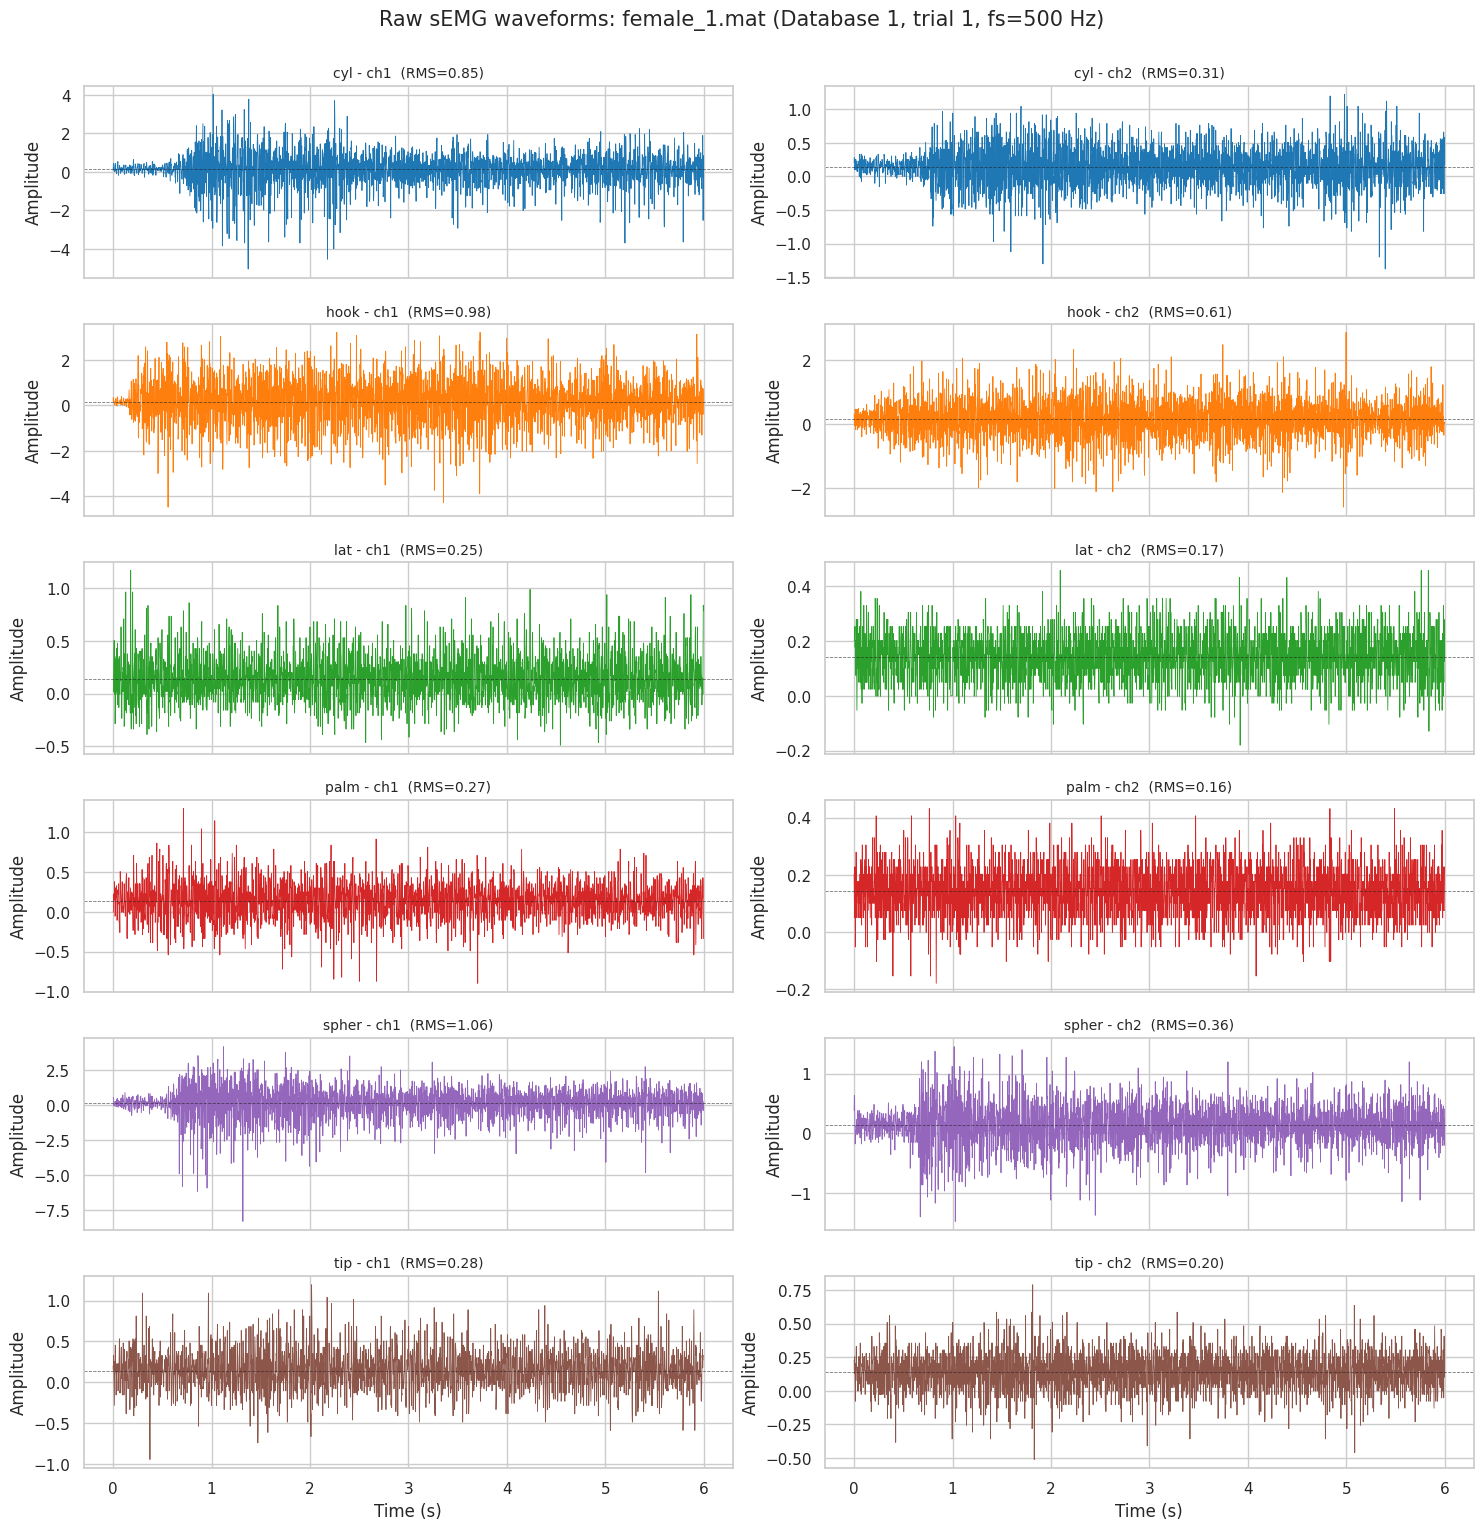

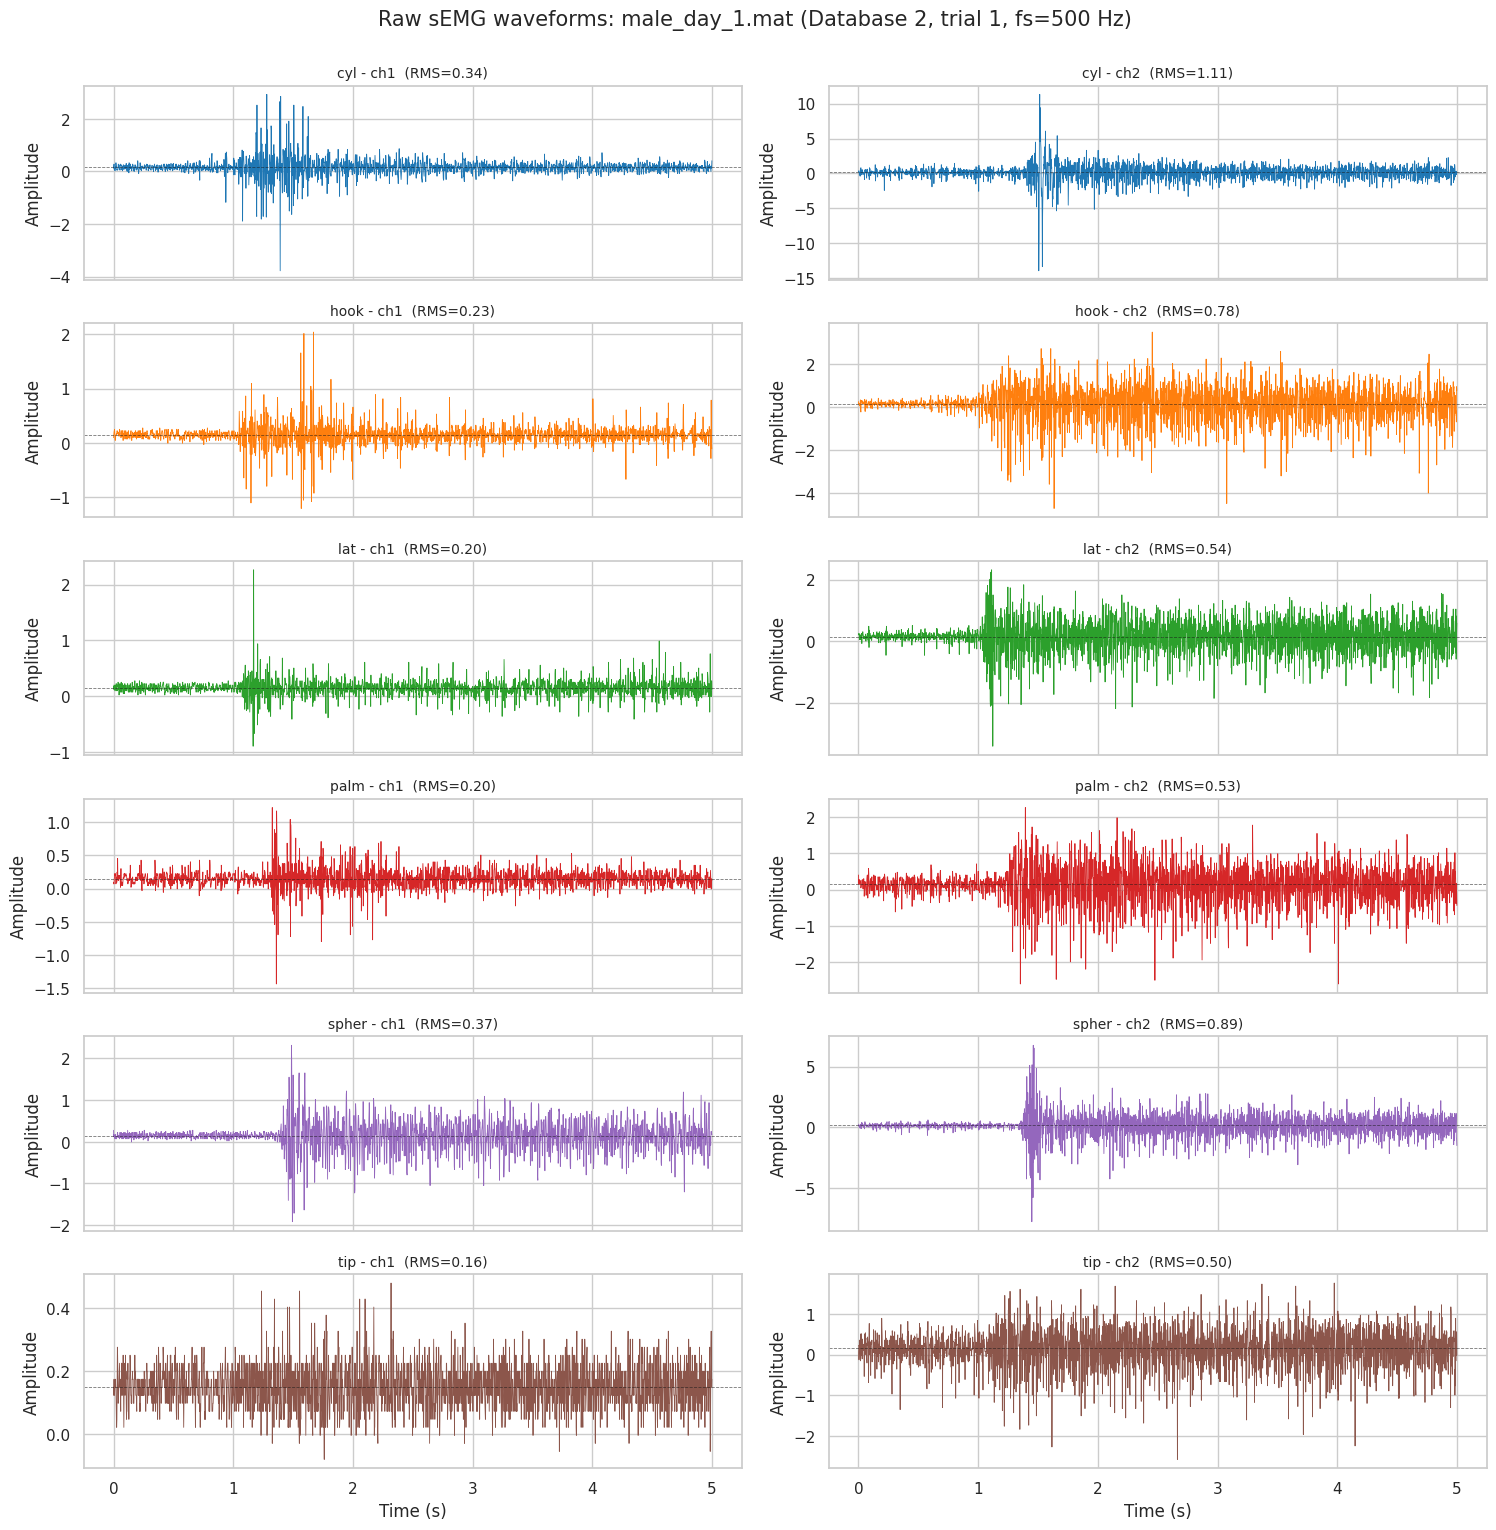

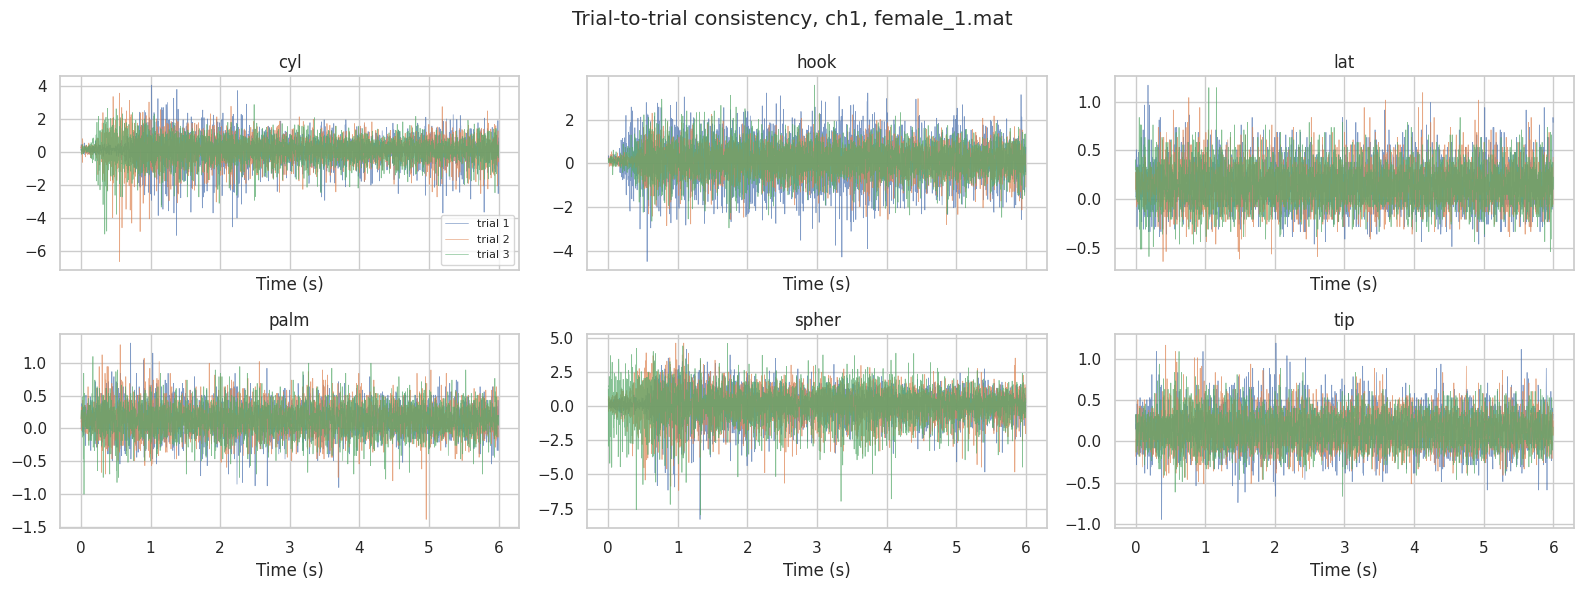

In [8]:
# Sampling rate per database (ASSUMPTION - edit from dataset documentation)
FS = {"Database 1": 500, "Database 2": 500, "Unknown": 500}
PAL = dict(zip(MOVEMENTS, sns.color_palette("tab10", len(MOVEMENTS))))

# One example file from each database (not only the first file in df)
example_files = df.groupby("database")["source_file"].first().tolist()
TRIAL = 1

for example_file in example_files:
    db = df.loc[df["source_file"] == example_file, "database"].iloc[0]
    fs = FS[db]

    fig, axes = plt.subplots(len(MOVEMENTS), len(CHANNELS),
                             figsize=(15, 2.6 * len(MOVEMENTS)),
                             sharex=True, squeeze=False)

    for i, movement in enumerate(MOVEMENTS):
        for j, channel in enumerate(CHANNELS):
            subset = df[(df["source_file"] == example_file) &
                        (df["movement"] == movement) &
                        (df["channel"] == channel) &
                        (df["trial"] == TRIAL)]
            ax = axes[i, j]
            if subset.empty:
                ax.set_visible(False); continue

            sig = subset.iloc[0]["signal"]
            t = np.arange(len(sig)) / fs
            ax.plot(t, sig, linewidth=0.6, color=PAL[movement])
            ax.axhline(sig.mean(), color="k", lw=0.6, ls="--", alpha=.6)   # DC offset
            ax.set_title(f"{movement} - {channel}  (RMS={np.sqrt(np.mean(sig**2)):.2f})", fontsize=10)
            ax.set_ylabel("Amplitude")

    for ax in axes[-1]:
        ax.set_xlabel("Time (s)")

    fig.suptitle(f"Raw sEMG waveforms: {Path(example_file).name} ({db}, trial {TRIAL}, fs={fs} Hz)",
                 fontsize=15)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()


example_file = example_files[0]
fig, axes = plt.subplots(2, 3, figsize=(16, 6), sharex=True)
for ax, movement in zip(axes.ravel(), MOVEMENTS):
    for tr in (1, 2, 3):
        s = df[(df.source_file == example_file) & (df.movement == movement) &
               (df.channel == CHANNELS[0]) & (df.trial == tr)].iloc[0]["signal"]
        ax.plot(np.arange(len(s)) / FS[df.loc[df.source_file == example_file, "database"].iloc[0]],
                s, lw=.5, alpha=.7, label=f"trial {tr}")
    ax.set_title(movement); ax.set_xlabel("Time (s)")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Trial-to-trial consistency, {CHANNELS[0]}, {Path(example_file).name}")
fig.tight_layout(); plt.show()

**Multiple trials comparison**

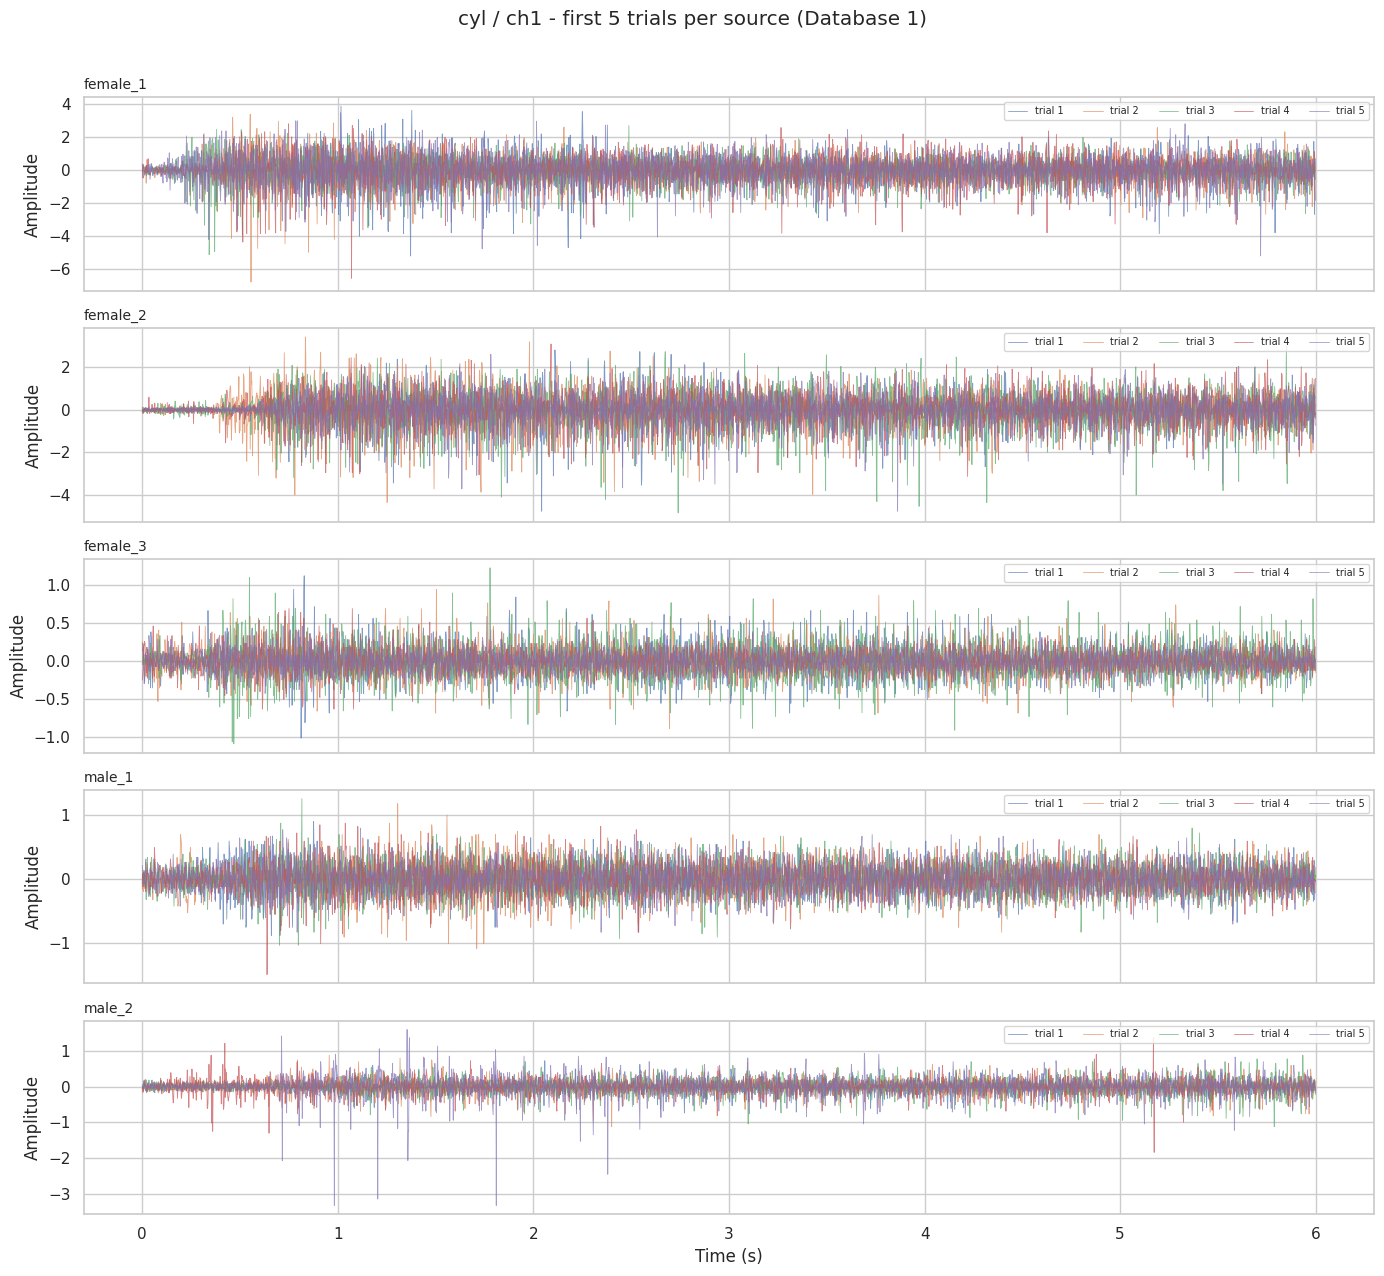

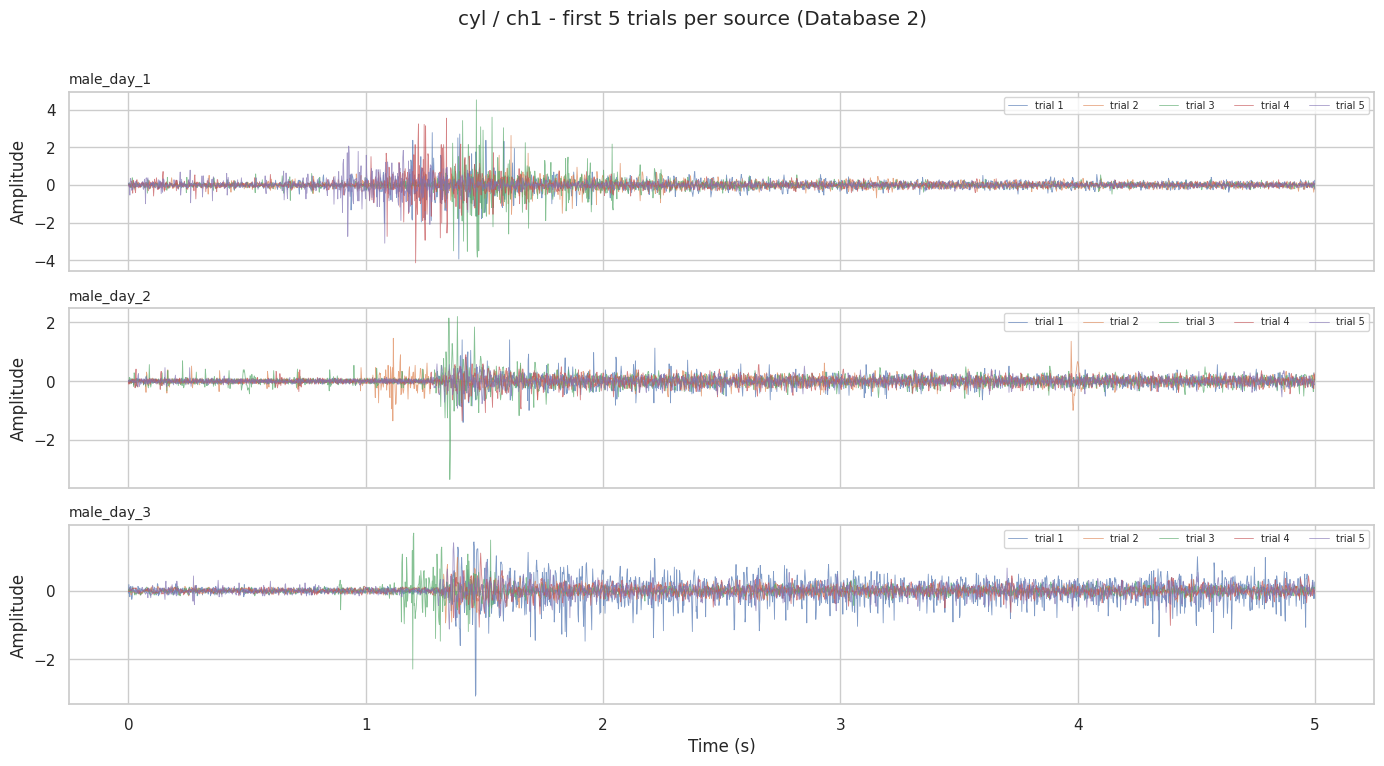

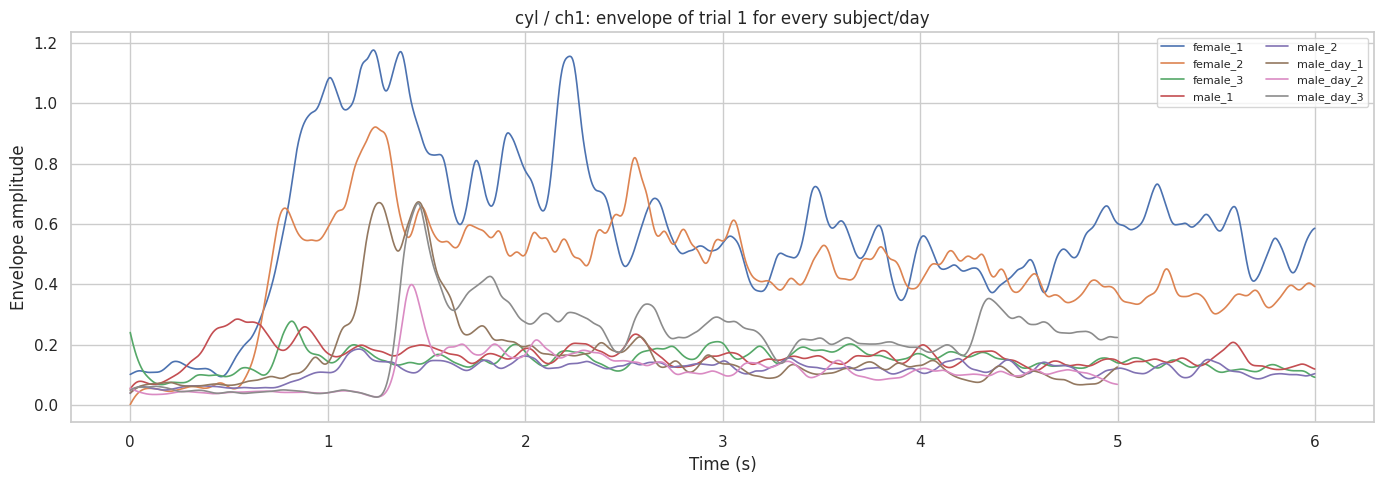

In [9]:
movement_to_plot = "cyl"
channel_to_plot  = "ch1"
n_trials_to_plot = 5
FS = globals().get("FS", {"Database 1": 500, "Database 2": 500, "Unknown": 500})  

subset = df[(df["movement"] == movement_to_plot) & (df["channel"] == channel_to_plot)]


for db, sub_db in subset.groupby("database"):
    fs = FS[db]
    files = sorted(sub_db["source_file"].unique())

    fig, axes = plt.subplots(len(files), 1, figsize=(14, 2.6 * len(files)), sharex=True, squeeze=False)
    for ax, f in zip(axes[:, 0], files):
        for _, row in sub_db[sub_db.source_file == f].sort_values("trial").head(n_trials_to_plot).iterrows():
            s = row["signal"]
            ax.plot(np.arange(len(s)) / fs, s - s.mean(),      # remove DC offset so trials align
                    linewidth=0.6, alpha=0.7, label=f'trial {row["trial"]}')
        ax.set_title(Path(f).stem, fontsize=10, loc="left")
        ax.set_ylabel("Amplitude")
        ax.legend(fontsize=7, ncol=n_trials_to_plot, loc="upper right")
    axes[-1, 0].set_xlabel("Time (s)")
    fig.suptitle(f"{movement_to_plot} / {channel_to_plot} - first {n_trials_to_plot} trials per source ({db})")
    fig.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

# Extra: same trial index across all sources, envelope + RMS, to compare subjects/days
from scipy.signal import butter, filtfilt
def env(s, fs, fc=5):
    b, a = butter(2, fc / (fs / 2), "low"); return filtfilt(b, a, np.abs(s - s.mean()))

plt.figure(figsize=(14, 5))
for f, g in subset[subset.trial == 1].groupby("source_file"):
    s = g.iloc[0]["signal"]; fs = FS[g.iloc[0]["database"]]
    plt.plot(np.arange(len(s)) / fs, env(s, fs), lw=1.2, label=Path(f).stem)
plt.title(f"{movement_to_plot} / {channel_to_plot}: envelope of trial 1 for every subject/day")
plt.xlabel("Time (s)"); plt.ylabel("Envelope amplitude"); plt.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Statistical feature extraction**

In [10]:
from scipy.stats import skew, kurtosis
from scipy.signal import welch

# Sampling rate per database (ASSUMPTION - edit from dataset documentation)
FS = globals().get("FS", {"Database 1": 500, "Database 2": 500, "Unknown": 500})

FEATURE_NAMES = ["dc_offset", "rms", "variance", "mav", "minimum", "maximum", "peak_to_peak",
                 "waveform_length", "zero_crossing_rate", "slope_sign_change_rate",
                 "skewness", "kurtosis", "mean_freq", "median_freq", "peak_freq"]

def extract_features(signal, fs=500):
    x = np.asarray(signal, dtype=np.float64)
    x = x[np.isfinite(x)]
    if len(x) < 3:
        return {k: np.nan for k in FEATURE_NAMES}

    dc = x.mean()
    xc = x - dc                       # remove DC offset (data has ~0.1-0.2 offset)
    d = np.diff(xc)

    # Frequency-domain features (Welch PSD)
    f, p = welch(xc, fs=fs, nperseg=min(256, len(xc)))
    cum = np.cumsum(p)

    return {
        "dc_offset": dc,
        "rms": np.sqrt(np.mean(xc ** 2)),
        "variance": np.var(xc),
        "mav": np.mean(np.abs(xc)),
        "minimum": xc.min(),
        "maximum": xc.max(),
        "peak_to_peak": np.ptp(xc),
        # normalised by length so 3000-sample and 2500-sample signals are comparable
        "waveform_length": np.mean(np.abs(d)),
        "zero_crossing_rate": np.mean(xc[:-1] * xc[1:] < 0),
        "slope_sign_change_rate": np.mean(d[:-1] * d[1:] < 0),
        "skewness": skew(xc),
        "kurtosis": kurtosis(xc),
        "mean_freq": np.sum(f * p) / np.sum(p),
        "median_freq": f[np.searchsorted(cum, cum[-1] / 2)],
        "peak_freq": f[np.argmax(p)],
    }

feature_records = []
group_cols = ["database", "source_file", "source_id", "movement", "trial"]

for keys, group in df.groupby(group_cols, sort=False):
    record = dict(zip(group_cols, keys))
    fs = FS[record["database"]]
    for channel in CHANNELS:
        rows = group[group["channel"] == channel]
        if rows.empty:
            continue
        for name, value in extract_features(rows.iloc[0]["signal"], fs).items():
            record[f"{name}_{channel}"] = value
    feature_records.append(record)

features_df = pd.DataFrame(feature_records)

# Cross-channel features (relationship between the two electrodes)
if len(CHANNELS) == 2:
    c1, c2 = CHANNELS
    features_df[f"rms_ratio_{c1}_{c2}"] = features_df[f"rms_{c1}"] / features_df[f"rms_{c2}"]

print("Feature table shape:", features_df.shape)
print("Total NaN:", int(features_df.isna().sum().sum()))
display(features_df.head())


from sklearn.feature_selection import f_classif
num_cols = features_df.select_dtypes("number").columns.drop("trial")
F, _ = f_classif(features_df[num_cols], features_df["movement"])
print("\nTop features by ANOVA F (movement):")
display(pd.Series(F, index=num_cols).sort_values(ascending=False).head(10).round(1))

Feature table shape: (2700, 36)
Total NaN: 0


,database,source_file,source_id,movement,trial,dc_offset_ch1,rms_ch1,variance_ch1,mav_ch1,minimum_ch1,...,peak_to_peak_ch2,waveform_length_ch2,zero_crossing_rate_ch2,slope_sign_change_rate_ch2,skewness_ch2,kurtosis_ch2,mean_freq_ch2,median_freq_ch2,peak_freq_ch2,rms_ratio_ch1_ch2
0,Database 1,Database 1/female_1.mat,female_1,cyl,1,0.141044,0.840739,0.706841,0.582472,-5.194674,...,2.601790,0.285509,0.467823,0.573049,-0.212539,1.456793,123.906020,113.281250,68.359375,3.018794
1,Database 1,Database 1/female_1.mat,female_1,cyl,2,0.140636,0.799169,0.638670,0.580774,-6.775367,...,2.448744,0.274053,0.459153,0.571714,-0.096236,1.182844,115.496563,99.609375,54.687500,2.904935
2,Database 1,Database 1/female_1.mat,female_1,cyl,3,0.138800,0.748804,0.560708,0.554243,-5.115925,...,2.091635,0.214915,0.453151,0.570047,-0.122747,0.806993,115.585081,101.562500,50.781250,3.520786
3,Database 1,Database 1/female_1.mat,female_1,cyl,4,0.139760,0.856790,0.734090,0.626328,-6.544977,...,2.270190,0.303371,0.464155,0.595397,-0.011459,0.814374,119.538516,103.515625,60.546875,2.884784
4,Database 1,Database 1/female_1.mat,female_1,cyl,5,0.138808,0.872892,0.761941,0.659154,-5.192438,...,1.913081,0.231714,0.431811,0.550700,0.051821,0.789817,106.340185,87.890625,52.734375,3.629049



Top features by ANOVA F (movement):


rms_ch1                393.3
mav_ch2                377.5
minimum_ch1            354.5
peak_to_peak_ch1       345.9
rms_ch2                343.6
mav_ch1                331.9
waveform_length_ch2    310.2
variance_ch2           274.4
maximum_ch1            262.6
variance_ch1           242.8
dtype: float64

**Feature summary and movement-wise statistics**

In [31]:

assert "features_df" in globals(), "features_df"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

feature_cols = [
    c for c in features_df.columns
    if c.endswith("_ch1") or c.endswith("_ch2")
]

print("Number of extracted features:", len(feature_cols))

print("\nOverall feature statistics:")
display(features_df[feature_cols].describe().T)

print("\nFeature statistics by movement:")
movement_stats = (
    features_df.groupby("movement")[feature_cols]
    .agg(["mean", "std"])
)

display(movement_stats)

Number of extracted features: 33

Overall feature statistics:


,count,mean,std,min,25%,50%,75%,max
dc_offset_ch1,2700.0,0.145783,0.003170,0.131481,0.143292,0.146826,0.147999,0.153120
rms_ch1,2700.0,0.302068,0.281608,0.053196,0.118088,0.192537,0.360124,1.749176
variance_ch1,2700.0,0.170519,0.342820,0.002830,0.013945,0.037071,0.129689,3.059618
mav_ch1,2700.0,0.199636,0.188958,0.042797,0.083735,0.122384,0.223647,1.204837
minimum_ch1,2700.0,-2.443971,2.522133,-15.757775,-3.244669,-1.428856,-0.688003,-0.149073
maximum_ch1,2700.0,1.922041,1.760472,0.152021,0.690179,1.326330,2.639309,14.672968
peak_to_peak_ch1,2700.0,4.366012,4.129049,0.331521,1.428092,2.805179,5.973758,27.847783
waveform_length_ch1,2700.0,0.236101,0.221517,0.039972,0.106331,0.153291,0.258009,1.492275
zero_crossing_rate_ch1,2700.0,0.418737,0.077042,0.220073,0.364146,0.405969,0.469907,0.637855
slope_sign_change_rate_ch1,2700.0,0.503655,0.068728,0.335223,0.447298,0.494896,0.559662,0.666133



Feature statistics by movement:


dc_offset_ch1             rms_ch1           variance_ch1             mav_ch1           minimum_ch1           maximum_ch1           peak_to_peak_ch1           waveform_length_ch1            \
                  mean       std      mean       std         mean       std      mean       std        mean       std        mean       std             mean       std                mean       std   
movement                                                                                                                                                                                               
cyl           0.145729  0.002780  0.282012  0.196393     0.118015  0.182070  0.187725  0.142760   -2.397070  1.653431    1.738162  0.986788         4.135232  2.543345            0.221267  0.181559   
hook          0.145910  0.003616  0.375782  0.281201     0.220110  0.313162  0.227567  0.200074   -3.788846  2.806738    3.163636  2.582671         6.952482  5.099676            0.276448  0.247981   
lat           0.145966  0.002812  0.160275  0.072636     0.030952  0.030649  0.108908  0.044089   -1.189153  1.026542    1.270791  1.032398         2.459944  1.980637            0.143682  0.063153   
palm          0.145758  0.003031  0.185408  0.150631     0.057015  0.096134  0.131670  0.107134   -1.235357  1.207603    1.198065  1.038489         2.433423  2.143230            0.162875  0.118813   
spher         0.145328  0.003680  0.669215  0.351501     0.571127  0.586796  0.440795  0.236780   -5.219473  3.058942    3.406993  1.565543         8.626466  4.462906            0.485187  0.295159   
tip           0.146007  0.002944  0.139717  0.079905     0.025891  0.035524  0.101150  0.054049   -0.833928  0.762479    0.754598  0.534507         1.588525  1.228386            0.127148  0.073599   

         zero_crossing_rate_ch1           slope_sign_change_rate_ch1           skewness_ch1           kurtosis_ch1            mean_freq_ch1            median_freq_ch1            peak_freq_ch1  \
                           mean       std                       mean       std         mean       std         mean        std          mean        std            mean        std          mean   
movement                                                                                                                                                                                          
cyl                    0.405218  0.042345                   0.501781  0.053222    -0.644484  0.866328    15.085684  19.746732     95.029967  12.169069       81.258681  15.618906     58.502604   
hook                   0.414062  0.068387                   0.498856  0.066222    -0.849195  1.902317    39.435902  57.769871    109.860060  16.117186      100.568576  20.899749     84.114583   
lat                    0.453110  0.089701                   0.526925  0.071479     0.157889  0.918903    14.223390  34.454070    114.620015  17.597087      102.803819  23.484981     82.625868   
palm                   0.441363  0.088221                   0.516860  0.074103     0.114750  0.592608     7.107779  13.519292    112.331646  16.112207      100.429688  21.918274     77.395833   
spher                  0.373189  0.050181                   0.472961  0.050554    -0.812899  0.625913     7.560742   7.206033     89.869080  12.666458       78.758681  15.065427     60.677083   
tip                    0.425480  0.082670                   0.504546  0.079563    -0.208503  0.660652     5.830021  18.257023    107.918515  19.975263       95.186632  28.343895     79.887153   

                    dc_offset_ch2             rms_ch2           variance_ch2             mav_ch2           minimum_ch2           maximum_ch2           peak_to_peak_ch2           waveform_length_ch2  \
                std          mean       std      mean       std         mean       std      mean       std        mean       std        mean       std             mean       std                mean   
movement                                          

** Waveformlength and zero crossing rate boxplots**

In [41]:
print(features_df.columns.tolist())

['database', 'source_file', 'source_id', 'movement', 'trial', 'dc_offset_ch1', 'rms_ch1', 'variance_ch1', 'mav_ch1', 'minimum_ch1', 'maximum_ch1', 'peak_to_peak_ch1', 'waveform_length_ch1', 'zero_crossing_rate_ch1', 'slope_sign_change_rate_ch1', 'skewness_ch1', 'kurtosis_ch1', 'mean_freq_ch1', 'median_freq_ch1', 'peak_freq_ch1', 'dc_offset_ch2', 'rms_ch2', 'variance_ch2', 'mav_ch2', 'minimum_ch2', 'maximum_ch2', 'peak_to_peak_ch2', 'waveform_length_ch2', 'zero_crossing_rate_ch2', 'slope_sign_change_rate_ch2', 'skewness_ch2', 'kurtosis_ch2', 'mean_freq_ch2', 'median_freq_ch2', 'peak_freq_ch2', 'rms_ratio_ch1_ch2', 'std_ch1', 'std_ch2']


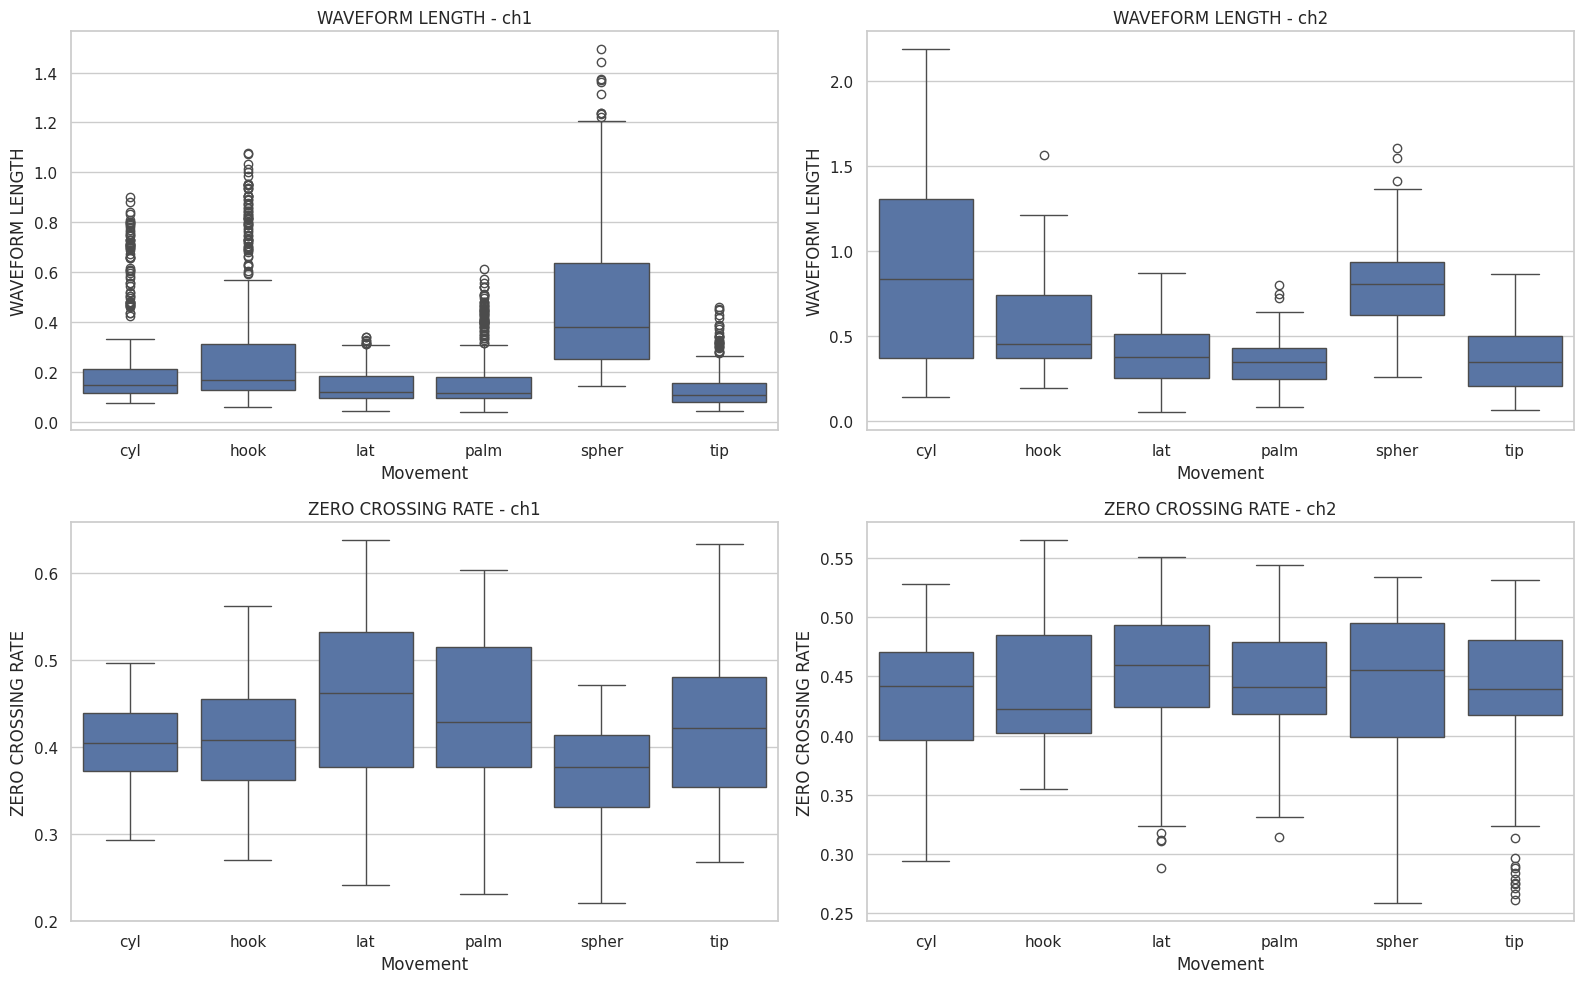

In [42]:

features_to_plot = ["waveform_length", "zero_crossing_rate"]

needed = [f"{feat}_{ch}" for feat in features_to_plot for ch in CHANNELS]
missing = [c for c in needed if c not in features_df.columns]
assert not missing, f"There is no feature: {missing}"

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for row_idx, feature in enumerate(features_to_plot):
    for col_idx, channel in enumerate(CHANNELS):
        ax = axes[row_idx, col_idx]
        
        sns.boxplot(
            data=features_df,
            x="movement",
            y=f"{feature}_{channel}",
            order=MOVEMENTS,
            ax=ax
        )
        
        ax.set_title(f"{feature.replace('_', ' ').upper()} - {channel}")
        ax.set_xlabel("Movement")
        ax.set_ylabel(feature.replace('_', ' ').upper())

plt.tight_layout()
plt.show()

**Boxplots of RMS,Zero crossing rate, median_freq and Waveform Length**

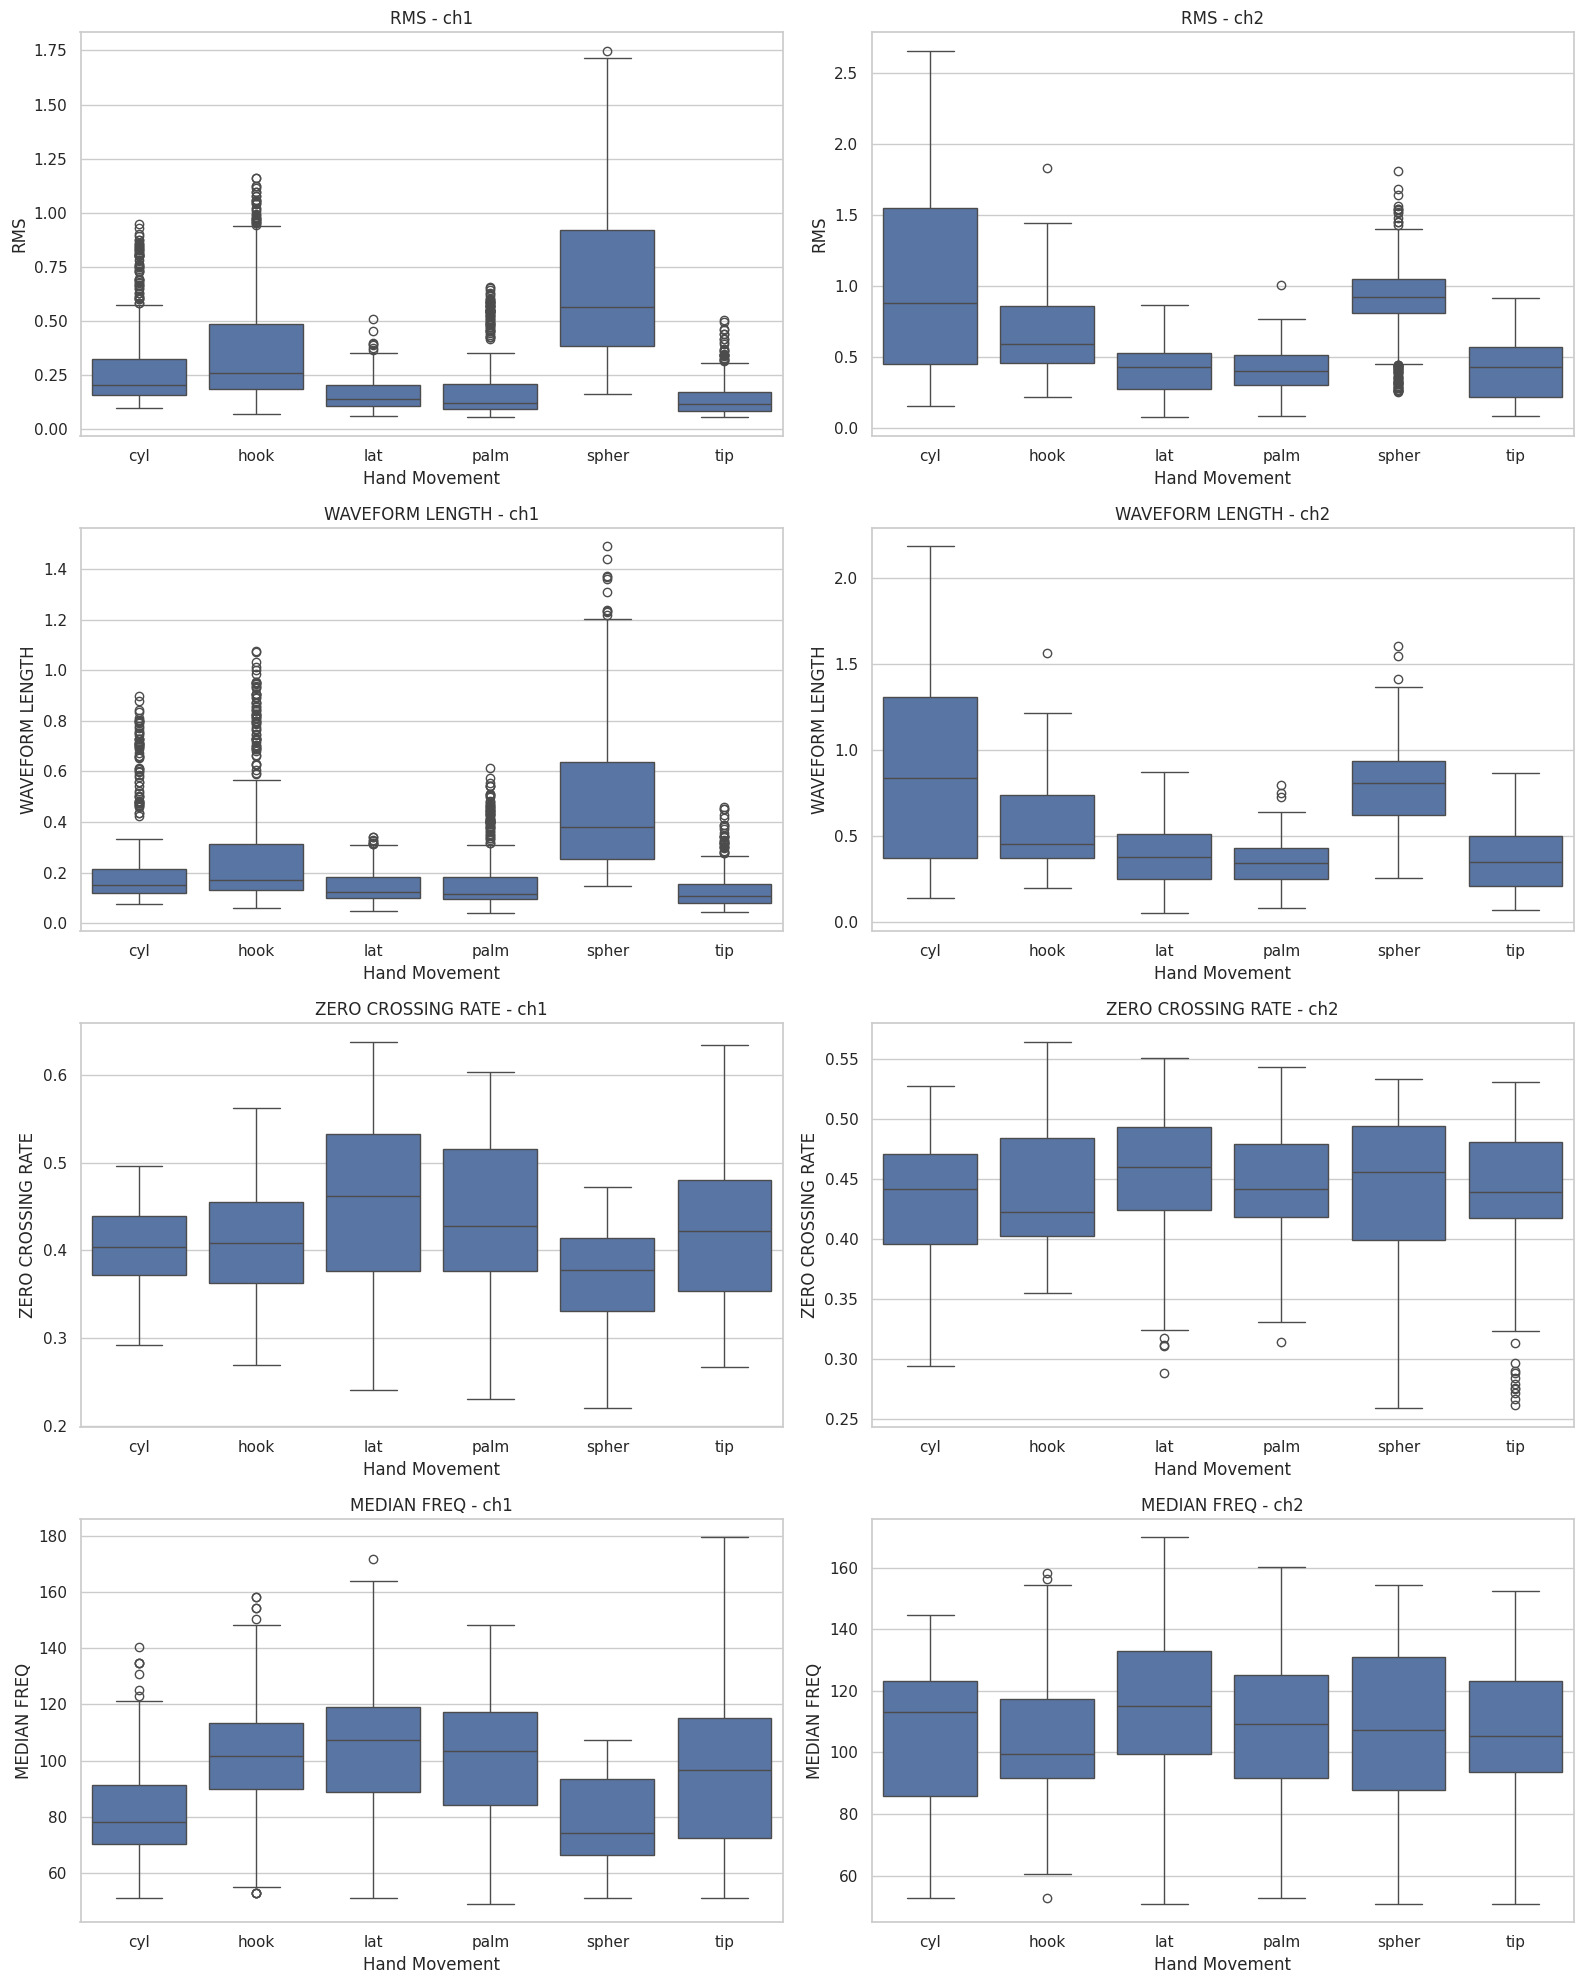

In [44]:
plot_features = [
    "rms",                  # 1. Amplitude 
    "waveform_length",      # 2. Complexity 
    "zero_crossing_rate",   # 3. Frequency/Oscillation 
    "median_freq"           # 4. Frequency Domain 
]

needed = [f"{feat}_{ch}" for feat in plot_features for ch in CHANNELS]
missing = [c for c in needed if c not in features_df.columns]
assert not missing, f"No feature: {missing}"

fig, axes = plt.subplots(len(plot_features), len(CHANNELS), figsize=(16, 20))

for i, feature in enumerate(plot_features):
    for j, channel in enumerate(CHANNELS):
        
        ax = axes[i, j]
        
        sns.boxplot(
            data=features_df,
            x="movement",
            y=f"{feature}_{channel}",
            order=MOVEMENTS,
            ax=ax
        )
        
        ax.set_title(f"{feature.replace('_', ' ').upper()} - {channel}")
        ax.set_xlabel("Hand Movement")
        ax.set_ylabel(feature.replace('_', ' ').upper())

plt.tight_layout()
plt.show()

**Feature correlation heatmap**

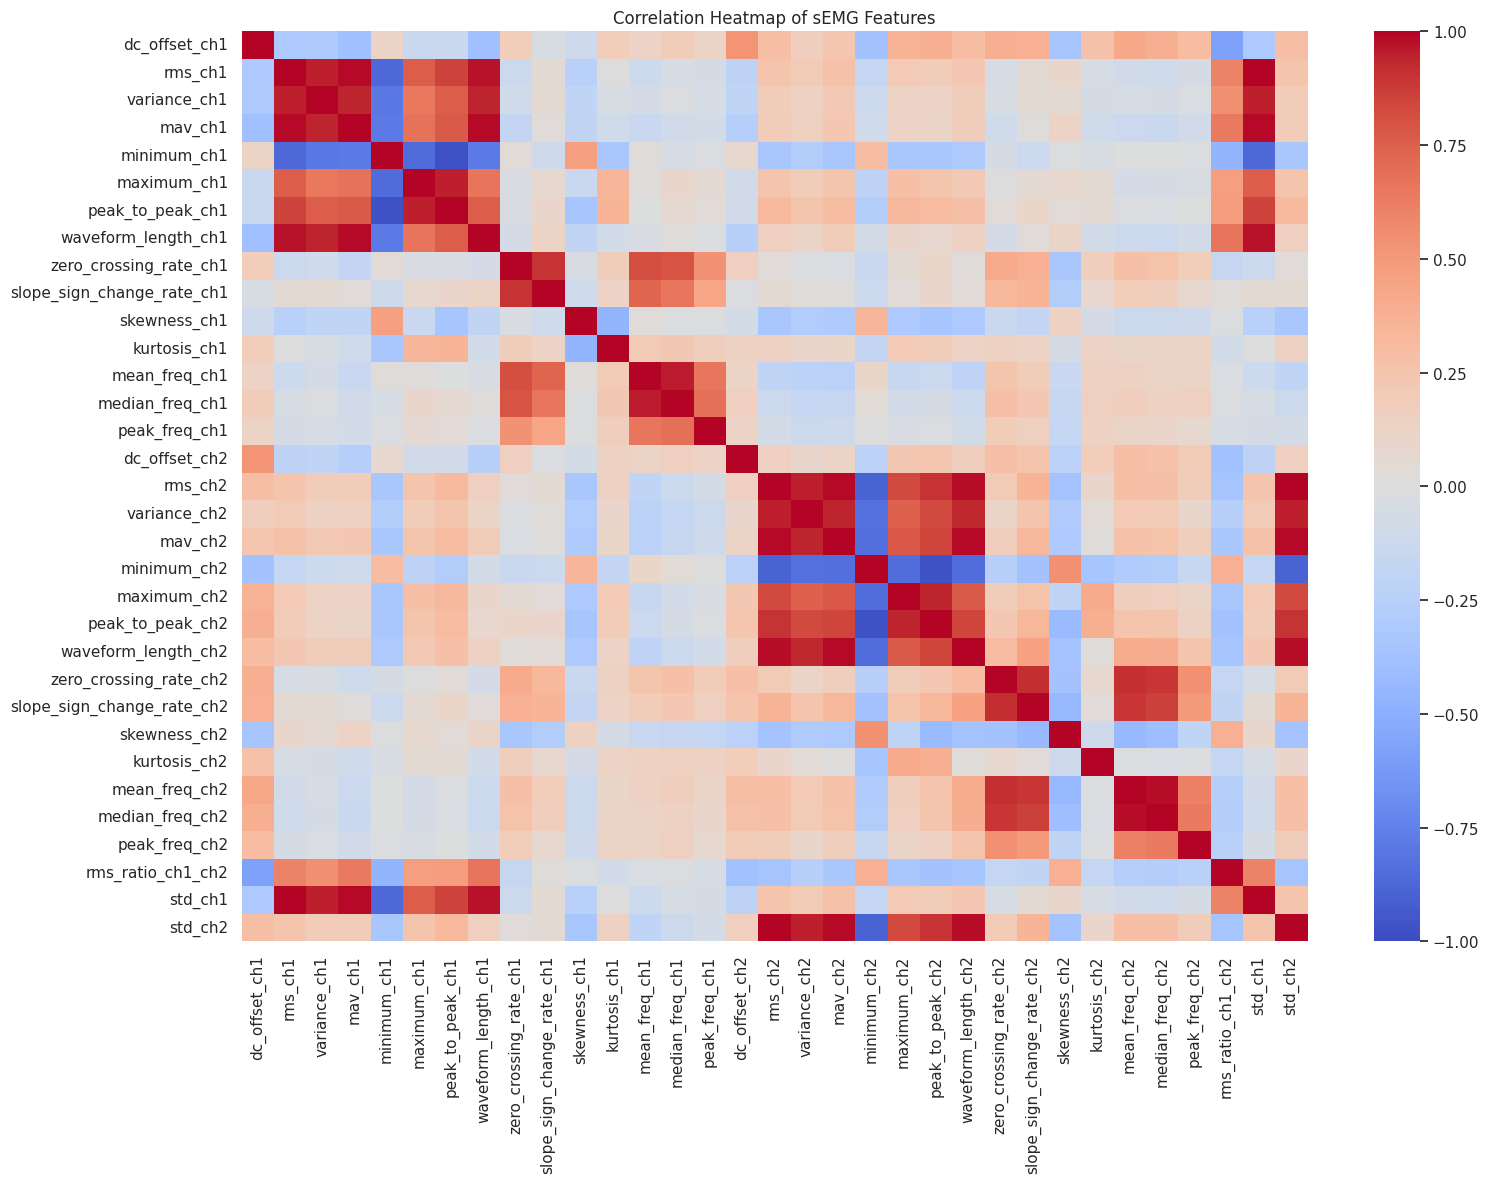

In [27]:

feature_cols = [
    c for c in features_df.columns
    if c.endswith("_ch1") or c.endswith("_ch2")
]

corr = features_df[feature_cols].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title("Correlation Heatmap of sEMG Features")
plt.tight_layout()
plt.show()

**Frequency analysis using Welch's PSD**

Available databases: ['Database 1' 'Database 2']

Database: Database 1
Example file: Database 1/female_1.mat


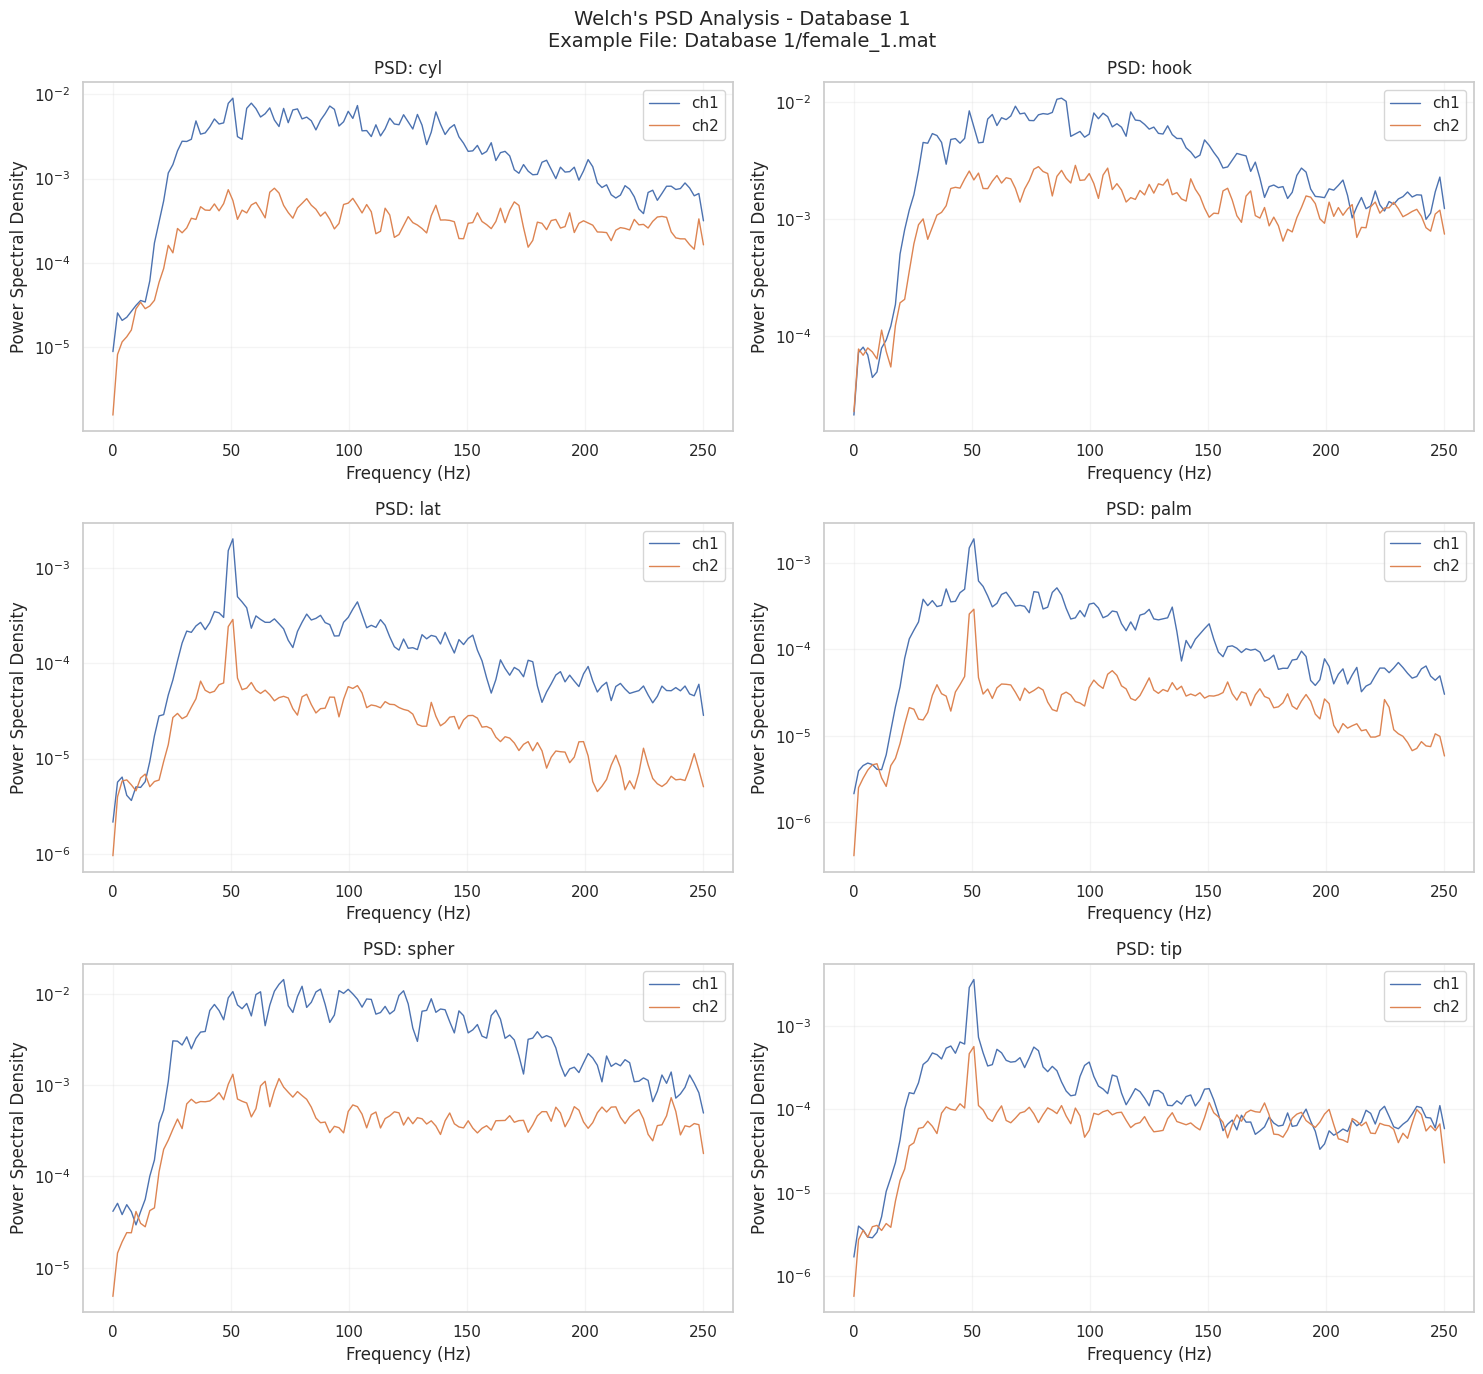


Database: Database 2
Example file: Database 2/male_day_1.mat


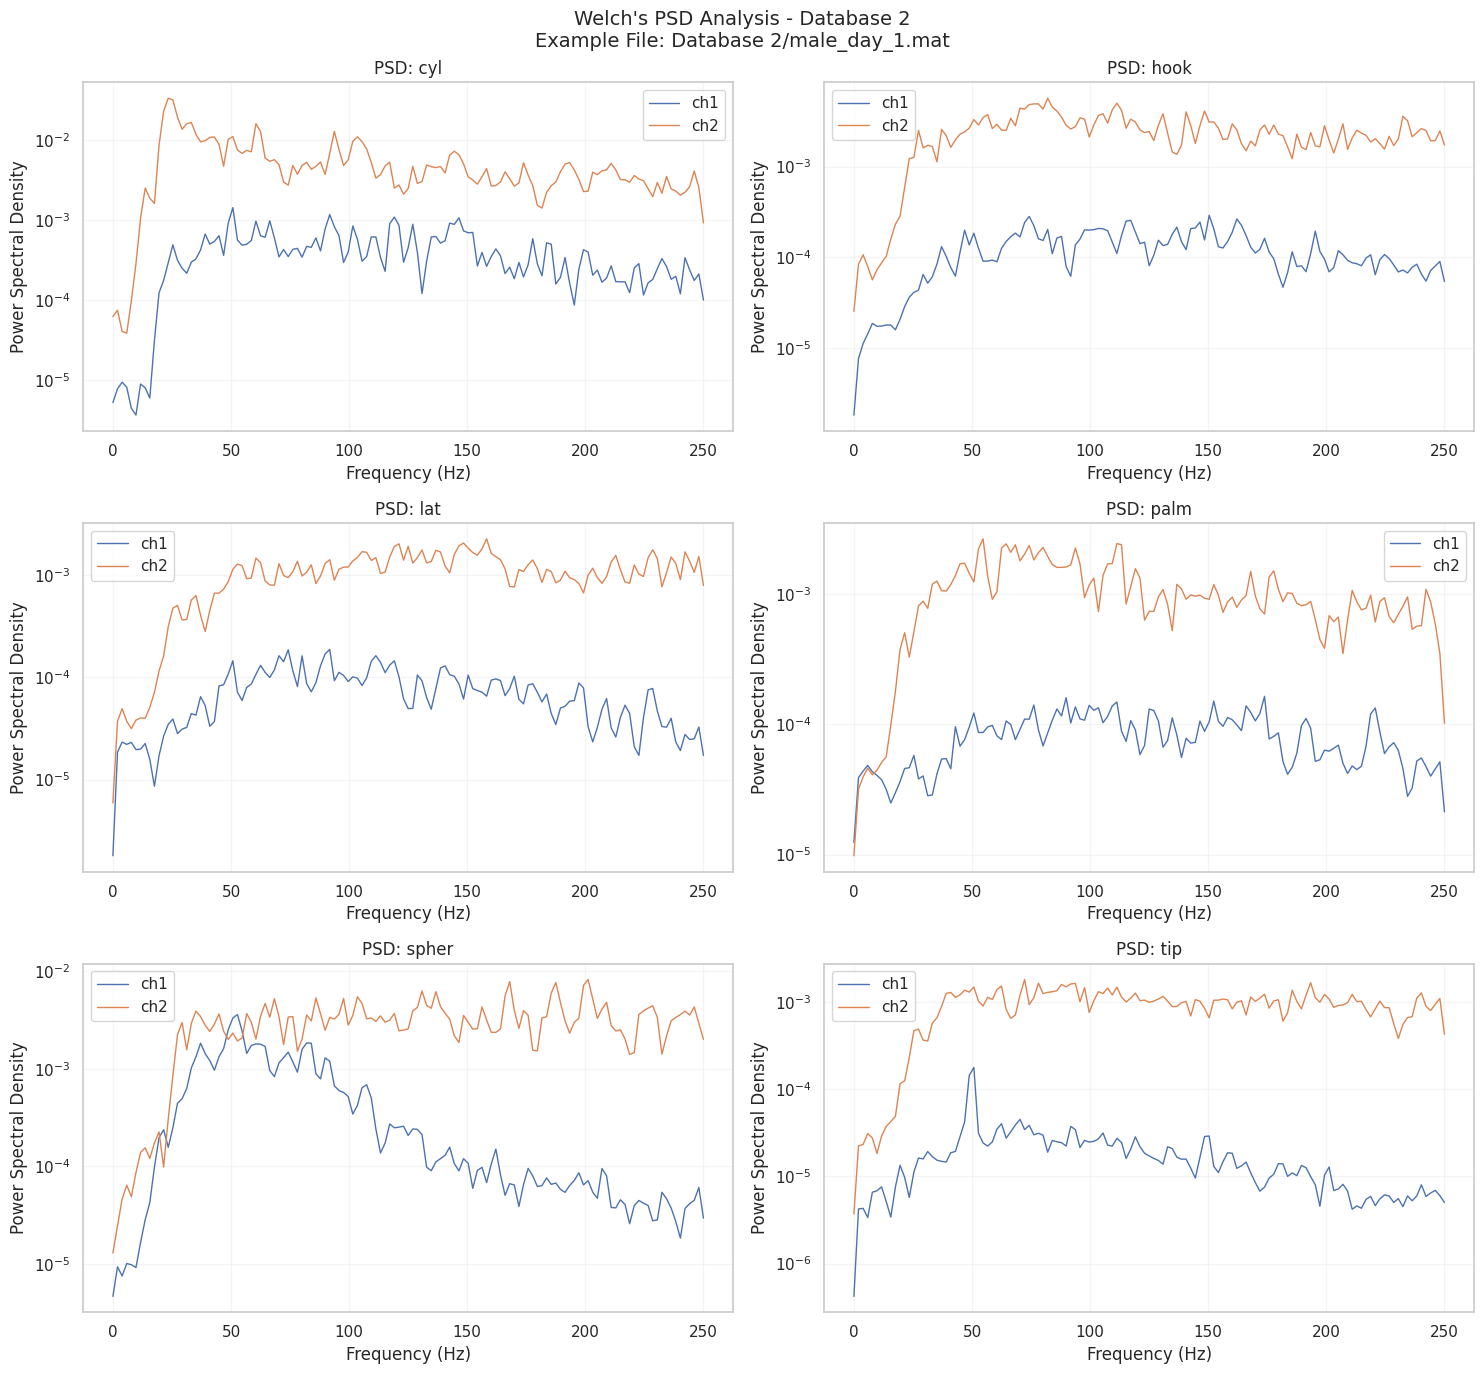

In [24]:

FS_PSD = 500  # Sampling frequency in Hz

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Check available databases
print("Available databases:", df["database"].unique())

databases = df["database"].dropna().unique()

for database in databases:

    db_data = df[df["database"] == database]

    # Select one example file from this database
    example_file = db_data["source_file"].iloc[0]

    print(f"\nDatabase: {database}")
    print("Example file:", example_file)

    fig, axes = plt.subplots(3, 2, figsize=(15, 14))
    axes = axes.ravel()

    for i, movement in enumerate(MOVEMENTS):

        ax = axes[i]

        for channel in CHANNELS:

            subset = db_data[
                (db_data["source_file"] == example_file) &
                (db_data["movement"] == movement) &
                (db_data["channel"] == channel) &
                (db_data["trial"] == 1)
            ]

            if subset.empty:
                continue

            sig = np.asarray(
                subset.iloc[0]["signal"],
                dtype=float
            )
            sig = sig[np.isfinite(sig)]

            if len(sig) < 8:
                continue

            freqs, psd = welch(
                sig,
                fs=FS_PSD,
                nperseg=min(256, len(sig))
            )

            # Avoid zero values on logarithmic Y-axis
            psd = np.maximum(psd, np.finfo(float).tiny)

            ax.plot(
                freqs,
                psd,
                label=channel,
                linewidth=1
            )

        ax.set_title(f"PSD: {movement}")
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Power Spectral Density")
        ax.set_yscale("log")
        ax.legend()
        ax.grid(alpha=0.2)

    # Hide unused subplots
    for k in range(len(MOVEMENTS), len(axes)):
        axes[k].axis("off")

    fig.suptitle(
        f"Welch's PSD Analysis - {database}\n"
        f"Example File: {example_file}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


**PCA visualization**

Explained variance ratio: [0.29061462 0.23127229]
Total variance explained: 52.19 %


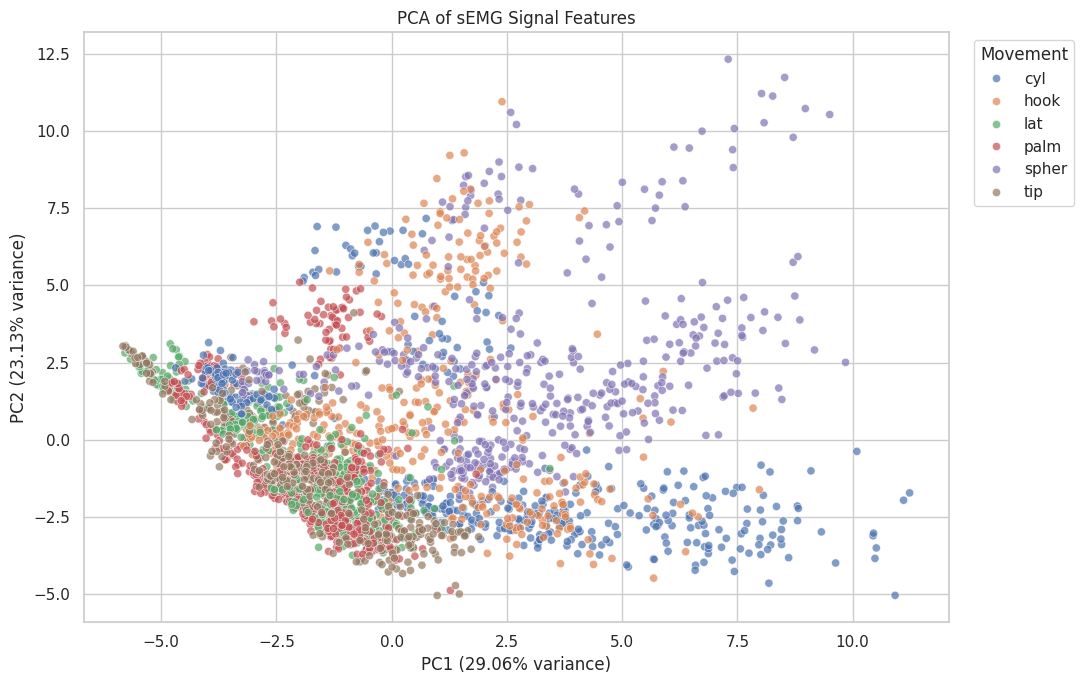

In [19]:

feature_cols = [
    c for c in features_df.columns
    if c.endswith("_ch1") or c.endswith("_ch2")
]

# Use only extracted signal features, not trial IDs or class labels.
X = features_df[feature_cols].replace([np.inf, -np.inf], np.nan)

# Median imputation is used only to make PCA executable
# if any feature values are missing.
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "movement": features_df["movement"].values
})

print("Explained variance ratio:", pca.explained_variance_ratio_)
print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="movement",
    hue_order=MOVEMENTS,
    alpha=0.7,
    s=35
)

plt.title("PCA of sEMG Signal Features")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)")
plt.legend(title="Movement", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Database-wise and source-wise comparison**

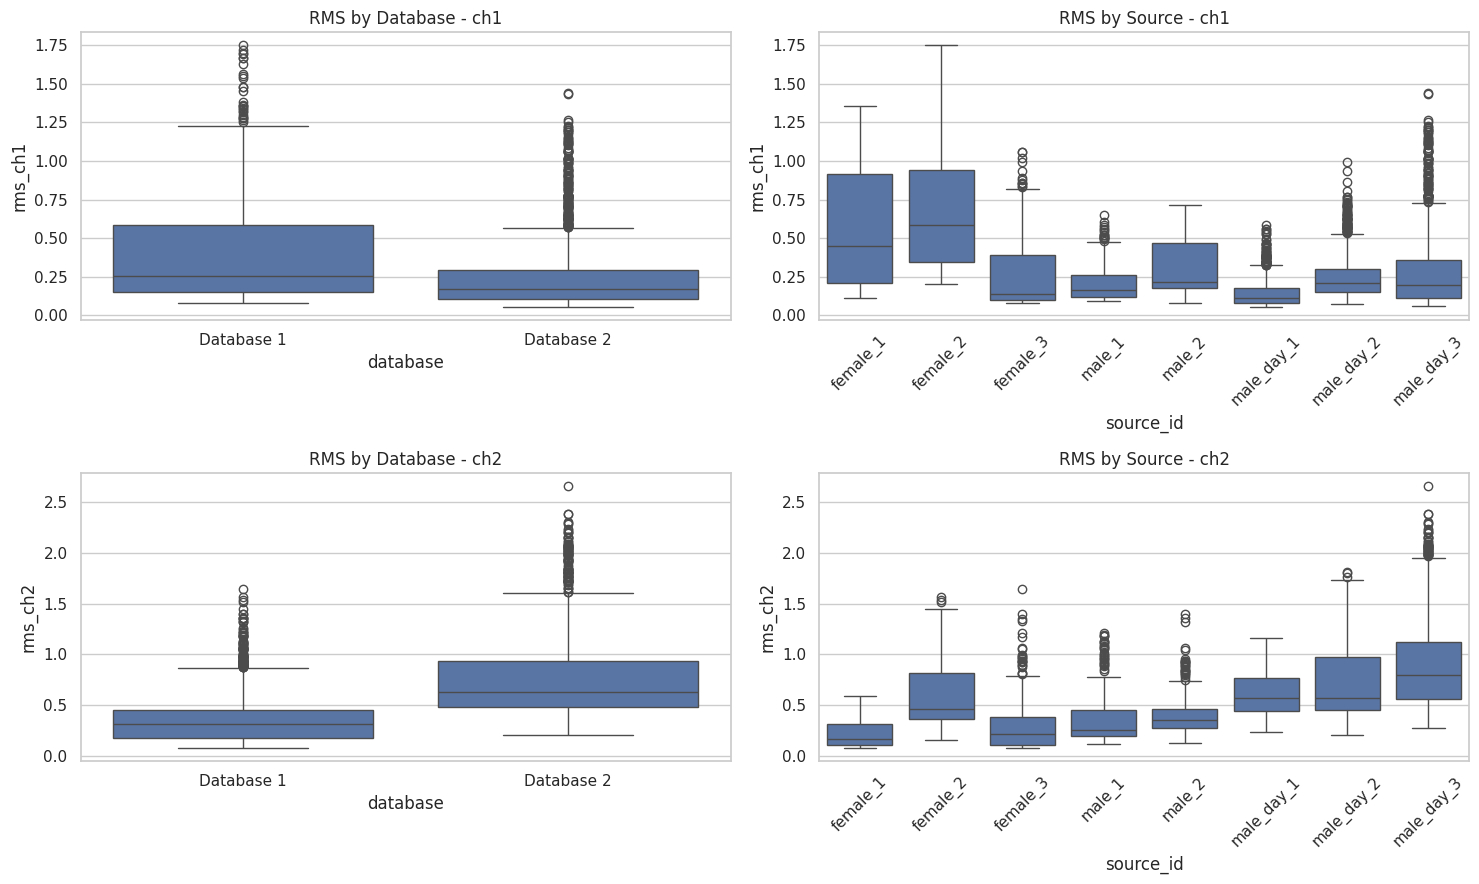

Trial counts by database and movement:


database,Database 1,Database 2
movement,,
cyl,150,300
hook,150,300
lat,150,300
palm,150,300
spher,150,300
tip,150,300


In [38]:
fig, axes = plt.subplots(len(CHANNELS), 2, figsize=(15, 9))
for r, ch in enumerate(CHANNELS):
    sns.boxplot(data=features_df, x="database", y=f"rms_{ch}", ax=axes[r, 0])
    sns.boxplot(data=features_df, x="source_id", y=f"rms_{ch}",
                order=sorted(features_df["source_id"].unique()), ax=axes[r, 1])
    axes[r, 0].set_title(f"RMS by Database - {ch}")
    axes[r, 1].set_title(f"RMS by Source - {ch}")
    axes[r, 1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Trial counts by database and movement:")
display(
    pd.crosstab(
        features_df["movement"],
        features_df["database"]
    )
)

**Save cell**

In [45]:

quality_records = []

for _, row in df.iterrows():
    sig = np.asarray(row["signal"], dtype=np.float64)
    finite = np.isfinite(sig)
    clean = sig[finite]

    quality_records.append({
        "database": row["database"],
        "source_id": row["source_id"],
        "movement": row["movement"],
        "trial": row["trial"],
        "channel": row["channel"],
        "n_samples": len(sig),
        "n_nan": int(np.isnan(sig).sum()),
        "n_inf": int(np.isinf(sig).sum()),
        "min": clean.min() if len(clean) else np.nan,
        "max": clean.max() if len(clean) else np.nan,
        "mean": clean.mean() if len(clean) else np.nan,
        "std": clean.std() if len(clean) else np.nan,
        "is_flat": bool(len(clean) == 0 or clean.std() == 0),
    })

quality_df = pd.DataFrame(quality_records)


trial_df = (
    df[["database", "source_file", "source_id", "movement", "trial"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("quality_df:", quality_df.shape, "(expected 5400 rows)")
print("trial_df  :", trial_df.shape, "(expected 2700 rows)")
print("Flat signals:", quality_df["is_flat"].sum())
print("Signals with NaN/Inf:", ((quality_df["n_nan"] > 0) | (quality_df["n_inf"] > 0)).sum())
display(quality_df.head())

quality_df: (5400, 13) (expected 5400 rows)
trial_df  : (2700, 5) (expected 2700 rows)
Flat signals: 0
Signals with NaN/Inf: 0


,database,source_id,movement,trial,channel,n_samples,n_nan,n_inf,min,max,mean,std,is_flat
0,Database 1,female_1,cyl,1,ch1,3000,0,0,-5.053630,4.024951,0.141044,0.840739,False
1,Database 1,female_1,cyl,2,ch1,3000,0,0,-6.634731,3.540420,0.140636,0.799169,False
2,Database 1,female_1,cyl,3,ch1,3000,0,0,-4.977125,2.851876,0.138800,0.748804,False
3,Database 1,female_1,cyl,4,ch1,3000,0,0,-6.405217,2.953883,0.139760,0.856790,False
4,Database 1,female_1,cyl,5,ch1,3000,0,0,-5.053630,3.616925,0.138808,0.872892,False


In [37]:
OUTPUT_DIR = Path("/kaggle/working/semg_eda_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

to_save = {
    "semg_extracted_features.csv": "features_df",
    "semg_signal_quality_report.csv": "quality_df",
    "semg_dataset_structure.csv": "summary_df",
    "semg_trial_metadata.csv": "trial_df",
    "semg_pca_coordinates.csv": "pca_df",
}

for filename, var_name in to_save.items():
    if var_name not in globals():
        print(f"SKIPPED: {var_name}  ({filename})")
        continue
    globals()[var_name].to_csv(OUTPUT_DIR / filename, index=False)

print("EDA files saved to:", OUTPUT_DIR)

for f in sorted(OUTPUT_DIR.iterdir()):
    print(f.name, "-", round(f.stat().st_size / 1024, 2), "KB")

EDA files saved to: /kaggle/working/semg_eda_results
semg_dataset_structure.csv - 4.95 KB
semg_extracted_features.csv - 1615.69 KB
semg_pca_coordinates.csv - 113.88 KB
semg_signal_quality_report.csv - 537.28 KB
semg_trial_metadata.csv - 141.5 KB
